In [1]:
import warnings, io
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy import stats

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.model_selection import (train_test_split, GridSearchCV, RandomizedSearchCV,
                                     cross_val_score, StratifiedKFold)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import (LinearRegression, RidgeCV, LassoCV, LogisticRegression, lasso_path)
from sklearn.tree import DecisionTreeRegressor, plot_tree, export_text
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA, FactorAnalysis
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error,
                             silhouette_score, calinski_harabasz_score, roc_auc_score,
                             roc_curve, confusion_matrix, classification_report)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (9, 5)
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_columns = 60

In [2]:
# Works in Google Colab (upload dialog) and locally (reads DATA_PATH).
DATA_PATH = "../data/Car_Sales.csv"   # local run: put the dataset here (.csv or .xlsx)

try:
    from google.colab import files
    uploaded = files.upload()
    fname = list(uploaded.keys())[0]
    buf = io.BytesIO(uploaded[fname])
except ImportError:
    fname, buf = DATA_PATH, DATA_PATH

df_raw = pd.read_excel(buf) if fname.lower().endswith((".xlsx", ".xls")) else pd.read_csv(buf)

print("Shape:", df_raw.shape)
display(df_raw.head())

Saving Car Sales.xlsx - DS9.csv to Car Sales.xlsx - DS9.csv
Shape: (2000, 43)


,Customer_ID,Customer_Name,Age,Gender,City,State,Annual_Income_INR,Occupation,Customer_Type,Car_ID,Brand,Model,Variant,Vehicle_Type,Fuel_Type,Transmission,Seating_Capacity,Engine_CC,Mileage_KMPL_or_Range_KM,Manufacturing_Year,Color,Sale_Date,Ex_Showroom_Price_INR,Discount_INR,Final_Selling_Price_INR,Finance_Required,Payment_Method,Loan_Amount_INR,Down_Payment_INR,Loan_Tenure_Years,Dealer_Name,Dealer_City,Dealer_State,Sales_Channel,Salesperson_ID,Booking_Source,Insurance_Purchased,Extended_Warranty,Old_Car_Exchange,Customer_Rating,Delivery_Time_Days,Registration_State,Sales_Status
0,IND00001,Vivaan Sharma,60,Male,Indore,Madhya Pradesh,886647,Teacher,Individual,CAR000001,Hyundai,Creta,Top,SUV,Petrol,Manual,7,1197,18.00,2024,White,28-03-2024,1583000,100863,1482137,No,Credit Card,0,1482137,0,Premium Wheels India,Indore,Madhya Pradesh,Dealer Referral,SP0029,Referral,No,Yes,Yes,3.20,15,Madhya Pradesh,Completed
1,IND00002,Priya Sharma,57,Female,Delhi,Delhi,1593303,Government Employee,Individual,CAR000002,Toyota,Glanza,Mid,Hatchback,Petrol,Automatic,5,1956,23.00,2023,White,10-07-2024,2006000,137571,1868429,Yes,Credit Card,1561815,306614,3,City Car Hub,Delhi,Delhi,Corporate Sales,SP0074,Website,Yes,Yes,Yes,4.90,6,Delhi,Completed
2,IND00003,Aditya Joshi,42,Male,Pune,Maharashtra,2682178,Government Employee,Individual,CAR000003,Hyundai,Venue,Base,SUV,Petrol,Automatic,5,1497,17.20,2025,Grey,21-02-2026,981000,11846,969154,Yes,UPI,696635,272519,5,City Car Hub,Pune,Maharashtra,Online Booking,SP0088,Social Media,Yes,Yes,Yes,3.10,20,Maharashtra,Completed
3,IND00004,Priya Gupta,65,Male,Pune,Maharashtra,2797188,Government Employee,Individual,CAR000004,Honda,Amaze,Top,Sedan,Petrol,Automatic,5,2198,20.90,2024,Red,30-09-2024,1588000,100547,1487453,Yes,UPI,1247062,240391,6,Metro Motors,Pune,Maharashtra,Dealer Referral,SP0047,Website,Yes,No,Yes,3.30,43,Maharashtra,Completed
4,IND00005,Aarav Das,25,Male,Lucknow,Uttar Pradesh,1264454,Government Employee,Individual,CAR000005,Hyundai,Venue,Top,SUV,Petrol,Automatic,5,2198,14.30,2023,Silver,23-05-2025,1276000,14593,1261407,Yes,Car Loan,999384,262023,7,City Car Hub,Lucknow,Uttar Pradesh,Dealer Referral,SP0021,Referral,Yes,No,Yes,4.40,48,Uttar Pradesh,Completed


In [3]:
df_raw.info()

print("\nMissing values (total):", int(df_raw.isna().sum().sum()))
print("Duplicate rows        :", int(df_raw.duplicated().sum()))
print("Duplicate Customer_ID :", int(df_raw["Customer_ID"].duplicated().sum()))
print("Duplicate Car_ID      :", int(df_raw["Car_ID"].duplicated().sum()))

print("\nUnique values per column:")
display(df_raw.nunique().sort_values().to_frame("n_unique").T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 43 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Customer_ID               2000 non-null   object 
 1   Customer_Name             2000 non-null   object 
 2   Age                       2000 non-null   int64  
 3   Gender                    2000 non-null   object 
 4   City                      2000 non-null   object 
 5   State                     2000 non-null   object 
 6   Annual_Income_INR         2000 non-null   int64  
 7   Occupation                2000 non-null   object 
 8   Customer_Type             2000 non-null   object 
 9   Car_ID                    2000 non-null   object 
 10  Brand                     2000 non-null   object 
 11  Model                     2000 non-null   object 
 12  Variant                   2000 non-null   object 
 13  Vehicle_Type              2000 non-null   object 
 14  Fuel_Typ

,Gender,Customer_Type,Transmission,Seating_Capacity,Finance_Required,Insurance_Purchased,Old_Car_Exchange,Extended_Warranty,Sales_Status,Variant,Manufacturing_Year,Sales_Channel,Payment_Method,Fuel_Type,Booking_Source,Color,Vehicle_Type,Loan_Tenure_Years,Dealer_Name,Engine_CC,Brand,Occupation,State,Registration_State,Dealer_State,Dealer_City,City,Customer_Rating,Model,Age,Delivery_Time_Days,Salesperson_ID,Customer_Name,Mileage_KMPL_or_Range_KM,Sale_Date,Loan_Amount_INR,Ex_Showroom_Price_INR,Annual_Income_INR,Discount_INR,Final_Selling_Price_INR,Down_Payment_INR,Car_ID,Customer_ID
n_unique,2,2,2,2,2,2,2,2,3,3,4,4,5,5,5,6,6,6,6,9,10,10,11,11,11,12,12,21,36,44,56,100,192,506,835,1404,1532,1990,1990,1999,2000,2000,2000


In [4]:
df = df_raw.copy()

# --- data types
df["Sale_Date"] = pd.to_datetime(df["Sale_Date"], format="%d-%m-%Y")

# --- redundant location columns (verify, then drop duplicates)
same = {
    "Dealer_City == City"        : (df["Dealer_City"] == df["City"]).all(),
    "Dealer_State == State"      : (df["Dealer_State"] == df["State"]).all(),
    "Registration_State == State": (df["Registration_State"] == df["State"]).all(),
}
print(same)
if all(same.values()):
    df = df.drop(columns=["Dealer_City", "Dealer_State", "Registration_State"])

# --- engineered features
df["Sale_Year"]    = df["Sale_Date"].dt.year
df["Sale_Month"]   = df["Sale_Date"].dt.month
df["Sale_Quarter"] = df["Sale_Date"].dt.to_period("Q").astype(str)
df["Sale_YM"]      = df["Sale_Date"].dt.to_period("M")

df["Discount_Pct"] = df["Discount_INR"] / df["Ex_Showroom_Price_INR"] * 100
df["Is_EV"]        = (df["Fuel_Type"] == "Electric").astype(int)
df["Is_Luxury"]    = df["Vehicle_Type"].str.contains("Luxury").astype(int)

# Mileage column mixes km/l (fuel cars) and range in km (EVs) -> split it
df["Fuel_Efficiency_KMPL"] = np.where(df["Is_EV"] == 0, df["Mileage_KMPL_or_Range_KM"], np.nan)
df["EV_Range_KM"]          = np.where(df["Is_EV"] == 1, df["Mileage_KMPL_or_Range_KM"], np.nan)

df["Years_Since_Manufacture"] = df["Sale_Year"] - df["Manufacturing_Year"]
df["Loan_to_Price"] = np.where(df["Finance_Required"] == "Yes",
                               df["Loan_Amount_INR"] / df["Final_Selling_Price_INR"], np.nan)

df["Age_Group"]   = pd.cut(df["Age"], bins=[0, 25, 35, 45, 55, 65, 120],
                           labels=["<=25", "26-35", "36-45", "46-55", "56-65", "65+"])
df["Income_Band"] = pd.qcut(df["Annual_Income_INR"], 4, labels=["Q1 (low)", "Q2", "Q3", "Q4 (high)"])
df["Cancelled"]   = (df["Sales_Status"] == "Cancelled").astype(int)
df["Financed"]    = (df["Finance_Required"] == "Yes").astype(int)

print("\nShape after wrangling:", df.shape)
display(df[["Sale_Date", "Discount_Pct", "Fuel_Efficiency_KMPL", "EV_Range_KM",
            "Years_Since_Manufacture", "Loan_to_Price", "Age_Group", "Income_Band"]].head())

{'Dealer_City == City': np.True_, 'Dealer_State == State': np.True_, 'Registration_State == State': np.True_}

Shape after wrangling: (2000, 55)


,Sale_Date,Discount_Pct,Fuel_Efficiency_KMPL,EV_Range_KM,Years_Since_Manufacture,Loan_to_Price,Age_Group,Income_Band
0,2024-03-28,6.37,18.00,NaN,0,NaN,56-65,Q2
1,2024-07-10,6.86,23.00,NaN,1,0.84,56-65,Q3
2,2026-02-21,1.21,17.20,NaN,1,0.72,36-45,Q4 (high)
3,2024-09-30,6.33,20.90,NaN,0,0.84,56-65,Q4 (high)
4,2025-05-23,1.14,14.30,NaN,2,0.79,<=25,Q3


In [5]:
fin = df[df["Financed"] == 1]
checks = {
    "Final price == Ex-showroom - Discount"            : np.allclose(df["Final_Selling_Price_INR"],
                                                                      df["Ex_Showroom_Price_INR"] - df["Discount_INR"]),
    "Loan + Down payment == Final price (financed)"    : np.allclose(fin["Loan_Amount_INR"] + fin["Down_Payment_INR"],
                                                                      fin["Final_Selling_Price_INR"]),
    "Loan amount & tenure are 0 for non-financed sales": bool(((df.loc[df.Financed == 0, "Loan_Amount_INR"] == 0) &
                                                                (df.loc[df.Financed == 0, "Loan_Tenure_Years"] == 0)).all()),
    "Engine_CC == 0 only for EVs"                      : bool(((df["Engine_CC"] == 0) == (df["Is_EV"] == 1)).all()),
    "Rows with Manufacturing_Year > Sale_Year"         : int((df["Years_Since_Manufacture"] < 0).sum()),
    "Rows with Age < 18"                               : int((df["Age"] < 18).sum()),
    "Loan-to-price range (financed)"                   : f"{fin['Loan_to_Price'].min():.2f} - {fin['Loan_to_Price'].max():.2f}",
    "Sale date range"                                  : f"{df['Sale_Date'].min().date()} -> {df['Sale_Date'].max().date()}",
}
display(pd.Series(checks, name="result").to_frame())

print("Finance_Required vs Payment_Method (a 'Car Loan' payment for a non-financed sale is inconsistent):")
display(pd.crosstab(df["Finance_Required"], df["Payment_Method"]))

print("Customer_Type vs Sales_Channel:")
display(pd.crosstab(df["Customer_Type"], df["Sales_Channel"]))

,result
Final price == Ex-showroom - Discount,True
Loan + Down payment == Final price (financed),True
Loan amount & tenure are 0 for non-financed sales,True
Engine_CC == 0 only for EVs,True
Rows with Manufacturing_Year > Sale_Year,566
Rows with Age < 18,0
Loan-to-price range (financed),0.60 - 0.85
Sale date range,2024-01-01 -> 2026-08-31


Finance_Required vs Payment_Method (a 'Car Loan' payment for a non-financed sale is inconsistent):


Payment_Method,Bank Transfer,Car Loan,Cash,Credit Card,UPI
Finance_Required,,,,,
No,120,112,117,113,134
Yes,255,284,274,277,314


Customer_Type vs Sales_Channel:


Sales_Channel,Corporate Sales,Dealer Referral,Online Booking,Showroom
Customer_Type,,,,
Corporate,59,41,47,50
Individual,438,460,448,457


In [6]:
num_cols_all = ["Age", "Annual_Income_INR", "Seating_Capacity", "Engine_CC", "Fuel_Efficiency_KMPL", "EV_Range_KM",
                "Ex_Showroom_Price_INR", "Discount_INR", "Discount_Pct", "Final_Selling_Price_INR",
                "Loan_Amount_INR", "Down_Payment_INR", "Loan_Tenure_Years", "Customer_Rating", "Delivery_Time_Days"]
display(df[num_cols_all].describe().T)

cat_cols_all = ["Gender", "Occupation", "Customer_Type", "Brand", "Vehicle_Type", "Fuel_Type", "Transmission",
                "Variant", "Color", "Finance_Required", "Payment_Method", "Sales_Channel", "Booking_Source",
                "Insurance_Purchased", "Extended_Warranty", "Old_Car_Exchange", "Sales_Status", "City"]
display(df[cat_cols_all].describe().T)

,count,mean,std,min,25%,50%,75%,max
Age,"2,000.00",42.84,12.60,22.00,32.00,43.00,53.00,65.00
Annual_Income_INR,"2,000.00","1,441,364.33","835,806.75","300,000.00","871,131.25","1,263,458.00","1,804,037.75","7,319,852.00"
Seating_Capacity,"2,000.00",5.58,0.91,5.00,5.00,5.00,7.00,7.00
Engine_CC,"2,000.00","1,292.46",703.73,0.00,998.00,"1,497.00","1,956.00","2,198.00"
Fuel_Efficiency_KMPL,"1,648.00",19.06,5.31,10.00,14.40,19.20,23.70,28.00
EV_Range_KM,352.00,417.55,74.17,281.30,360.12,417.80,480.75,548.70
Ex_Showroom_Price_INR,"2,000.00","2,953,658.00","2,491,187.89","676,000.00","1,448,000.00","1,907,500.00","2,899,750.00","11,753,000.00"
Discount_INR,"2,000.00","159,819.65","163,696.25","9,370.00","62,675.00","106,198.00","175,522.75","1,114,282.00"
Discount_Pct,"2,000.00",5.52,2.59,1.00,3.37,5.55,7.75,10.00
Final_Selling_Price_INR,"2,000.00","2,793,838.35","2,364,751.53","621,784.00","1,350,742.50","1,805,023.50","2,739,189.50","10,651,156.00"


,count,unique,top,freq
Gender,2000,2,Male,1014
Occupation,2000,10,Lawyer,225
Customer_Type,2000,2,Individual,1803
Brand,2000,10,Toyota,218
Vehicle_Type,2000,6,SUV,1041
Fuel_Type,2000,5,Petrol,895
Transmission,2000,2,Manual,1008
Variant,2000,3,Mid,680
Color,2000,6,Red,343
Finance_Required,2000,2,Yes,1404


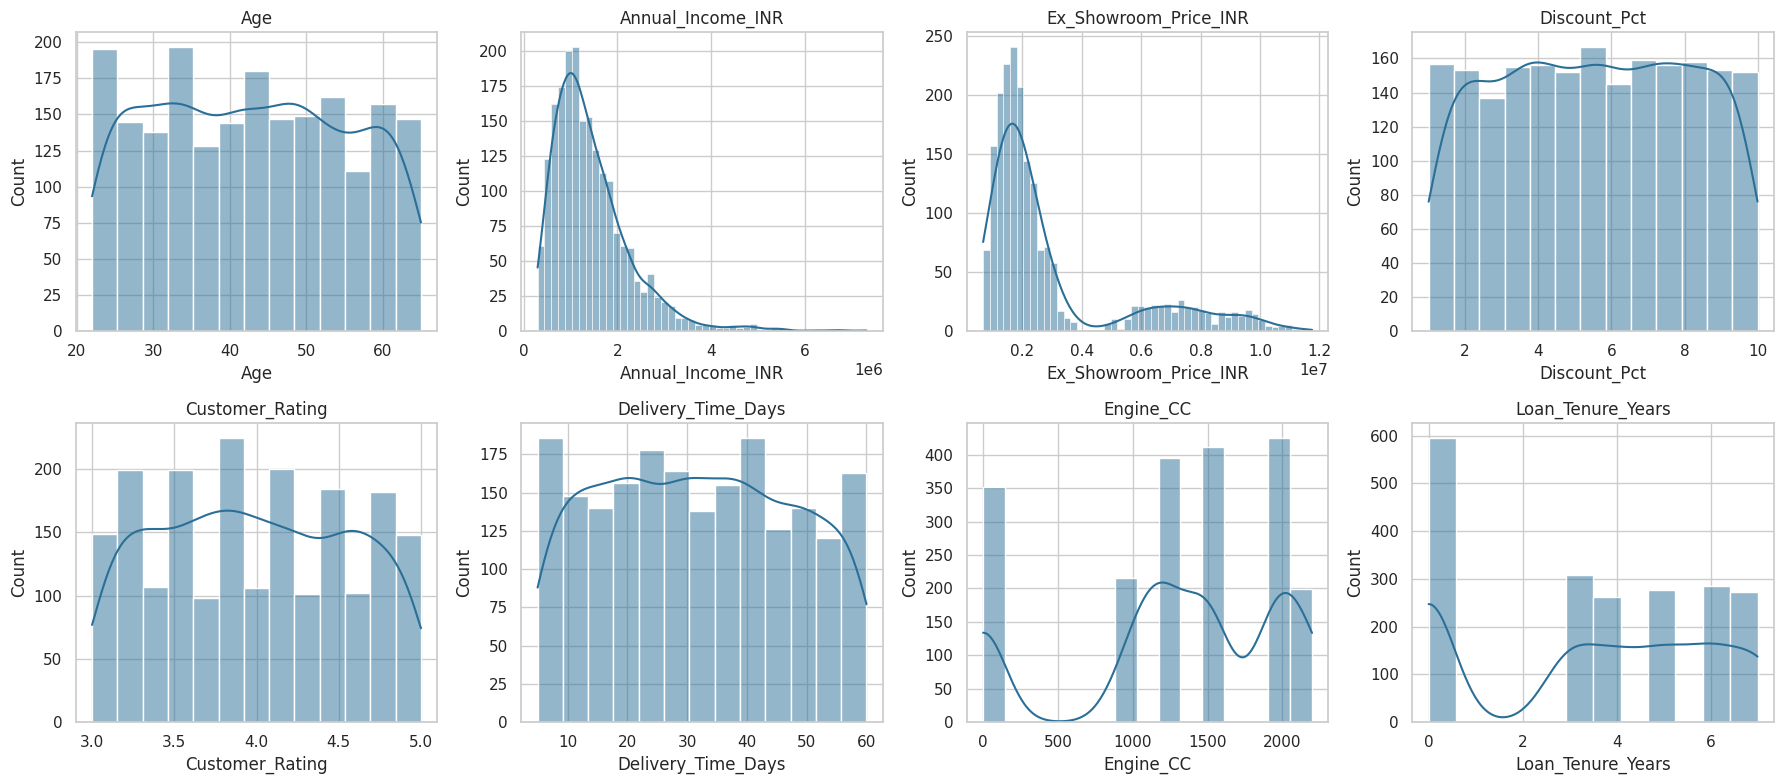

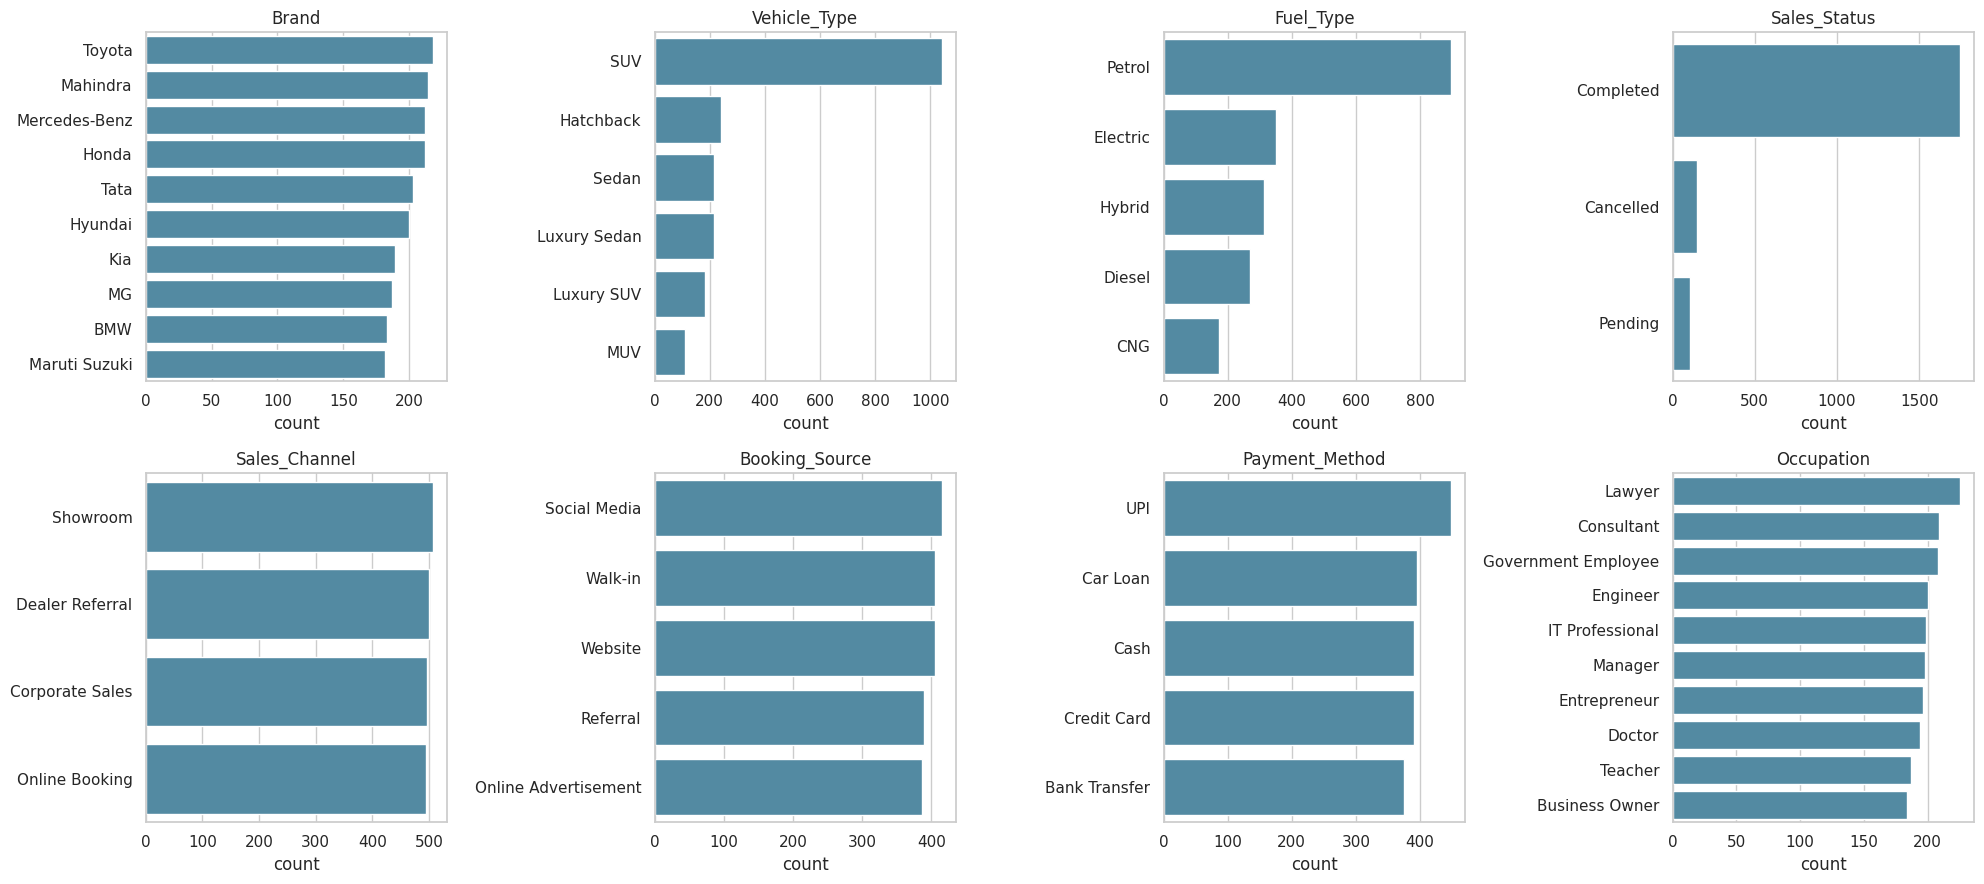

In [7]:
plot_nums = ["Age", "Annual_Income_INR", "Ex_Showroom_Price_INR", "Discount_Pct",
             "Customer_Rating", "Delivery_Time_Days", "Engine_CC", "Loan_Tenure_Years"]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.ravel(), plot_nums):
    sns.histplot(df[c], kde=True, ax=ax, color="#2a6f97")
    ax.set_title(c)
plt.tight_layout(); plt.show()

plot_cats = ["Brand", "Vehicle_Type", "Fuel_Type", "Sales_Status", "Sales_Channel", "Booking_Source",
             "Payment_Method", "Occupation"]
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, c in zip(axes.ravel(), plot_cats):
    order = df[c].value_counts().index
    sns.countplot(y=df[c], order=order, ax=ax, color="#468faf")
    ax.set_title(c); ax.set_ylabel("")
plt.tight_layout(); plt.show()

,lower_fence,upper_fence,n_outliers,pct_outliers
Age,0.50,84.50,0.00,0.00
Annual_Income_INR,"-528,228.50","3,203,397.50",71.00,3.55
Ex_Showroom_Price_INR,"-729,625.00","5,077,375.00",382.00,19.10
Discount_INR,"-106,596.62","344,794.38",223.00,11.15
Discount_Pct,-3.19,14.32,0.00,0.00
Customer_Rating,2.00,6.00,0.00,0.00
Delivery_Time_Days,-22.50,85.50,0.00,0.00


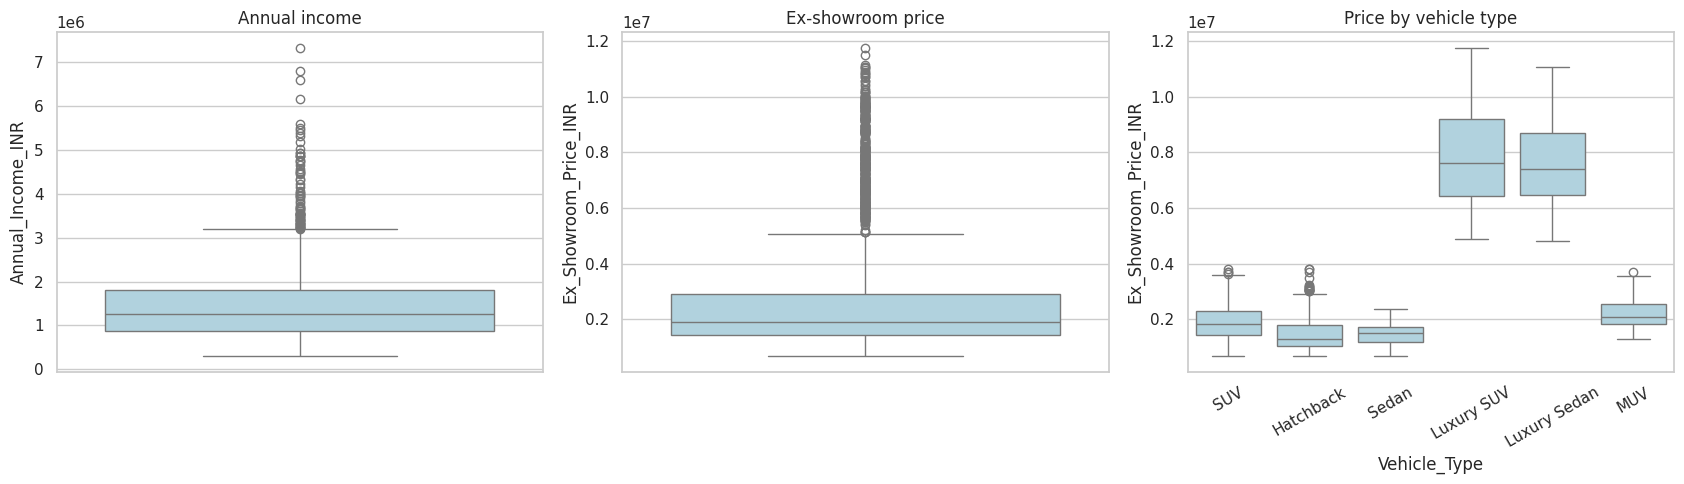

Note: high-price and high-income outliers are genuine (luxury brands / high earners), so they are kept.
      Skewness is handled with a log transform where needed.
Skewness: {'Annual_Income_INR': 1.83, 'Ex_Showroom_Price_INR': 1.62}


In [8]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return pd.Series({"lower_fence": lo, "upper_fence": hi,
                      "n_outliers": int(((s < lo) | (s > hi)).sum()),
                      "pct_outliers": ((s < lo) | (s > hi)).mean() * 100})

out_cols = ["Age", "Annual_Income_INR", "Ex_Showroom_Price_INR", "Discount_INR", "Discount_Pct",
            "Customer_Rating", "Delivery_Time_Days"]
display(df[out_cols].apply(iqr_outliers).T)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
sns.boxplot(y=df["Annual_Income_INR"], ax=axes[0], color="#a9d6e5"); axes[0].set_title("Annual income")
sns.boxplot(y=df["Ex_Showroom_Price_INR"], ax=axes[1], color="#a9d6e5"); axes[1].set_title("Ex-showroom price")
sns.boxplot(x="Vehicle_Type", y="Ex_Showroom_Price_INR", data=df, ax=axes[2], color="#a9d6e5")
axes[2].set_title("Price by vehicle type"); axes[2].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

print("Note: high-price and high-income outliers are genuine (luxury brands / high earners), so they are kept.")
print("      Skewness is handled with a log transform where needed.")
print("Skewness:", df[["Annual_Income_INR", "Ex_Showroom_Price_INR"]].skew().round(2).to_dict())

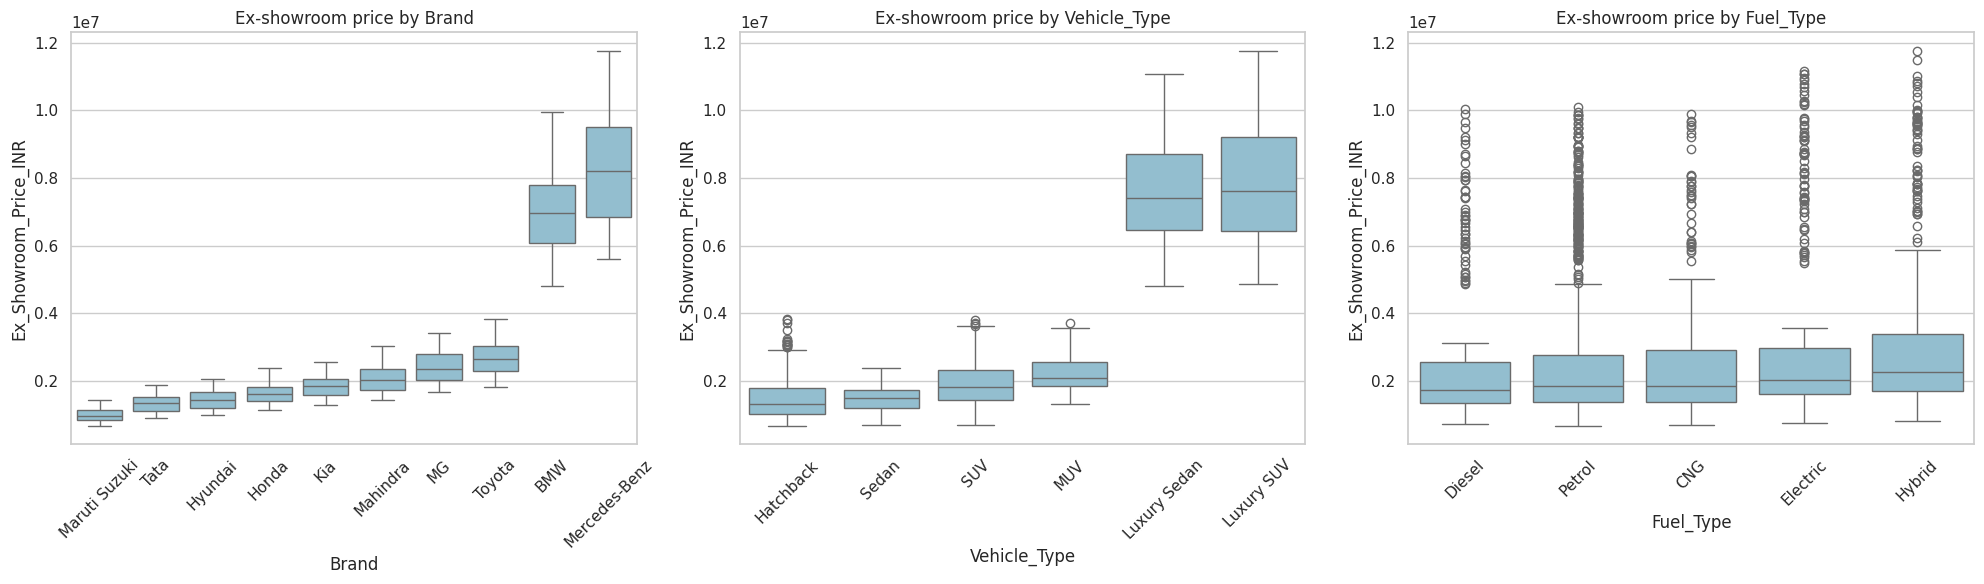

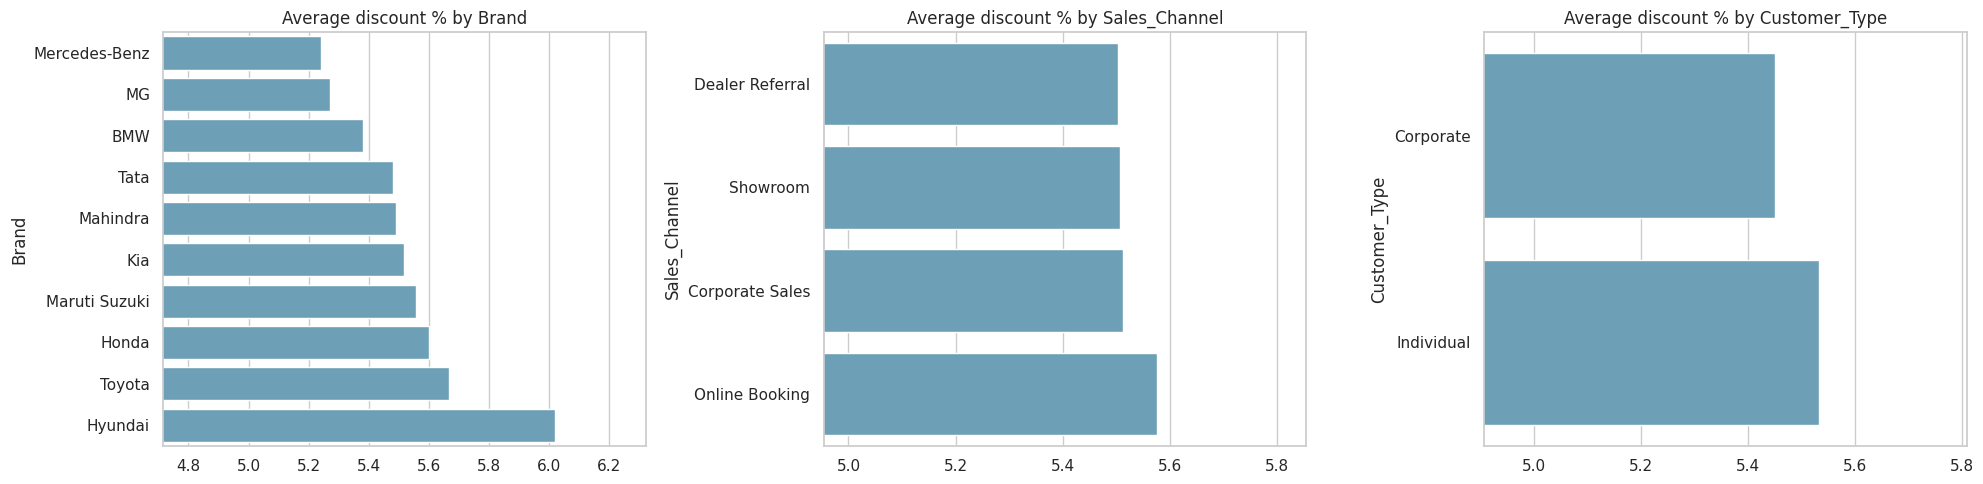

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, c in zip(axes, ["Brand", "Vehicle_Type", "Fuel_Type"]):
    order = df.groupby(c)["Ex_Showroom_Price_INR"].median().sort_values().index
    sns.boxplot(x=c, y="Ex_Showroom_Price_INR", data=df, order=order, ax=ax, color="#89c2d9")
    ax.set_title(f"Ex-showroom price by {c}"); ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, c in zip(axes, ["Brand", "Sales_Channel", "Customer_Type"]):
    d = df.groupby(c)["Discount_Pct"].mean().sort_values()
    sns.barplot(x=d.values, y=d.index, ax=ax, color="#61a5c2")
    ax.set_title(f"Average discount % by {c}"); ax.set_xlim(d.min() * 0.9, d.max() * 1.05)
plt.tight_layout(); plt.show()

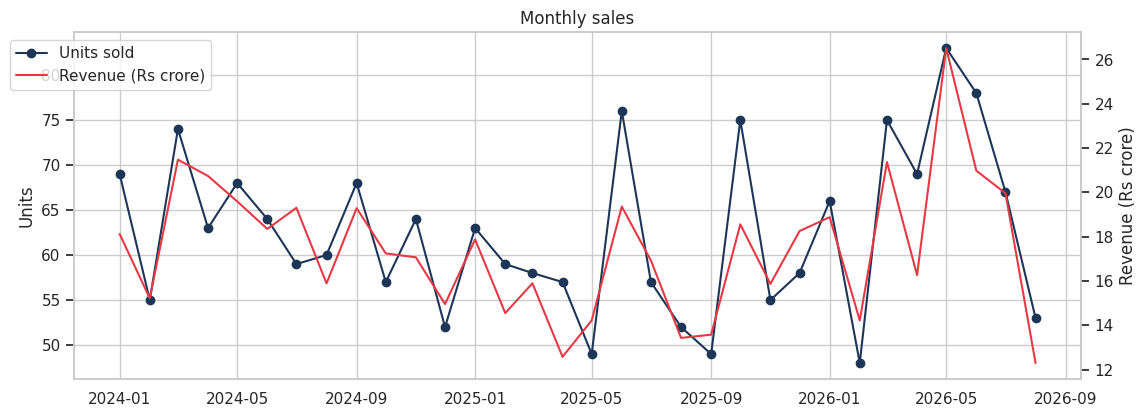

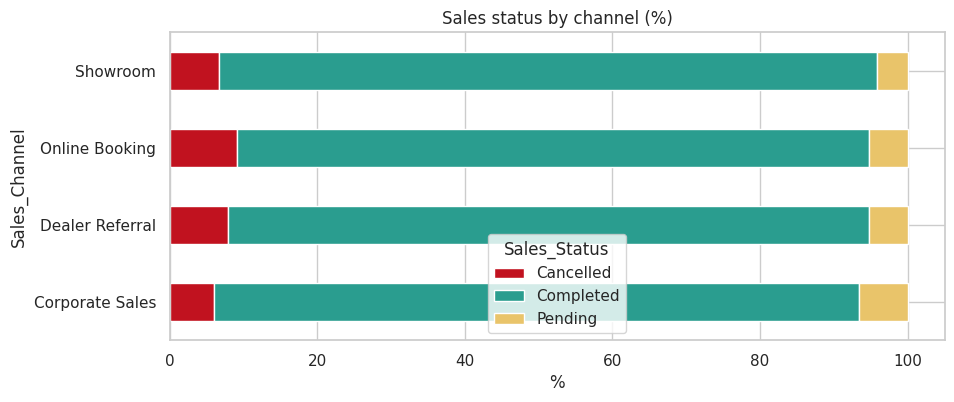

In [10]:
# Sales trend
monthly = df.groupby("Sale_YM").agg(units=("Car_ID", "count"),
                                    revenue_cr=("Final_Selling_Price_INR", lambda s: s.sum() / 1e7))
monthly.index = monthly.index.to_timestamp()
fig, ax1 = plt.subplots(figsize=(13, 4.5))
ax1.plot(monthly.index, monthly["units"], marker="o", color="#1d3557", label="Units sold")
ax1.set_ylabel("Units"); ax1.set_title("Monthly sales")
ax2 = ax1.twinx(); ax2.plot(monthly.index, monthly["revenue_cr"], color="#e63946", label="Revenue (Rs crore)")
ax2.set_ylabel("Revenue (Rs crore)"); ax2.grid(False)
fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.88)); plt.show()

# Sales status by channel
ct = pd.crosstab(df["Sales_Channel"], df["Sales_Status"], normalize="index") * 100
ct.plot(kind="barh", stacked=True, figsize=(10, 4), color=["#c1121f", "#2a9d8f", "#e9c46a"])
plt.title("Sales status by channel (%)"); plt.xlabel("%"); plt.show()

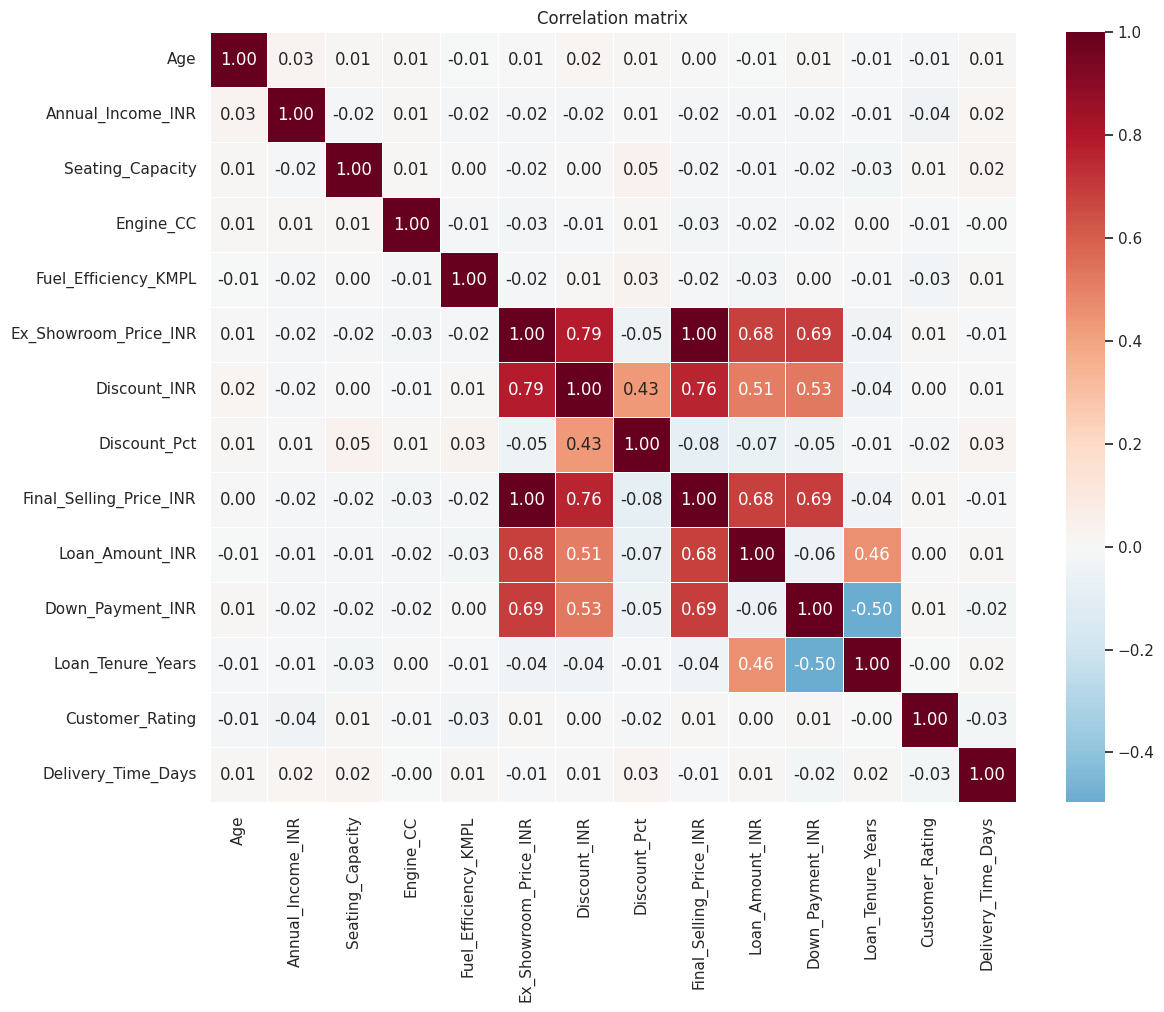

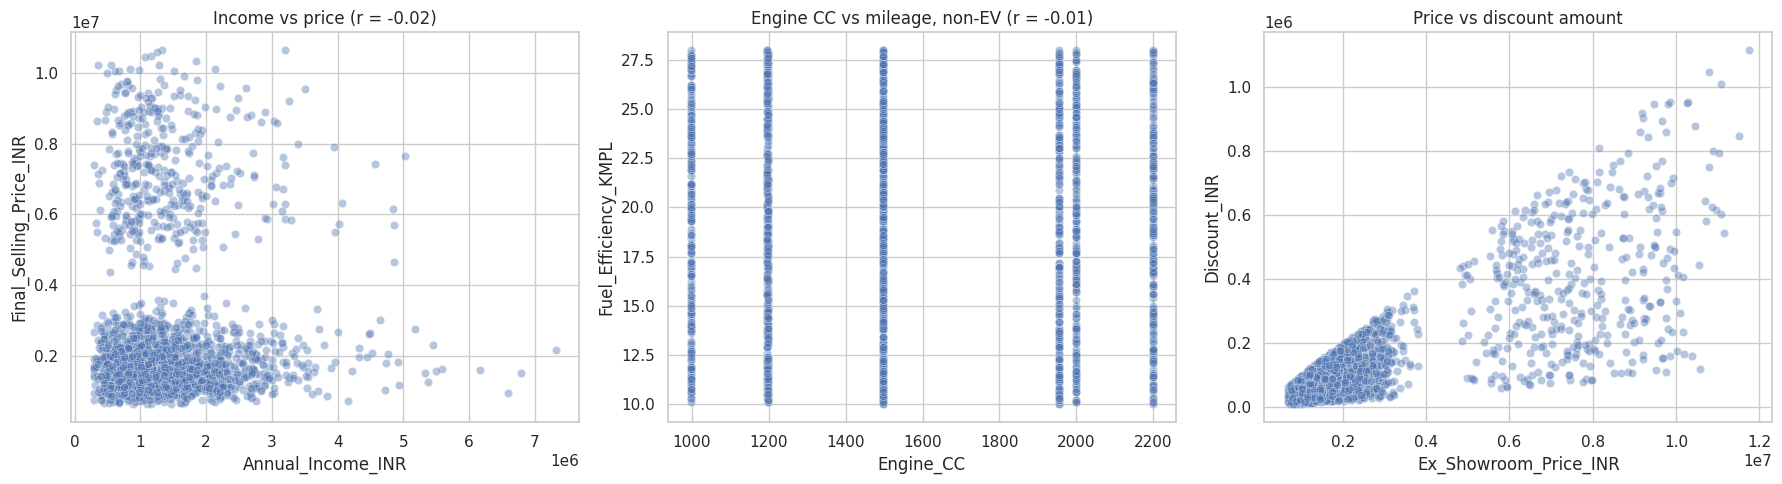

In [11]:
corr_cols = ["Age", "Annual_Income_INR", "Seating_Capacity", "Engine_CC", "Fuel_Efficiency_KMPL",
             "Ex_Showroom_Price_INR", "Discount_INR", "Discount_Pct", "Final_Selling_Price_INR",
             "Loan_Amount_INR", "Down_Payment_INR", "Loan_Tenure_Years", "Customer_Rating", "Delivery_Time_Days"]
plt.figure(figsize=(13, 10))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, linewidths=.5)
plt.title("Correlation matrix"); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.scatterplot(x="Annual_Income_INR", y="Final_Selling_Price_INR", data=df, alpha=.4, ax=axes[0])
axes[0].set_title(f"Income vs price (r = {df.Annual_Income_INR.corr(df.Final_Selling_Price_INR):.2f})")
nonev = df[df.Is_EV == 0]
sns.scatterplot(x="Engine_CC", y="Fuel_Efficiency_KMPL", data=nonev, alpha=.4, ax=axes[1])
axes[1].set_title(f"Engine CC vs mileage, non-EV (r = {nonev.Engine_CC.corr(nonev.Fuel_Efficiency_KMPL):.2f})")
sns.scatterplot(x="Ex_Showroom_Price_INR", y="Discount_INR", data=df, alpha=.4, ax=axes[2])
axes[2].set_title("Price vs discount amount")
plt.tight_layout(); plt.show()

In [12]:
# Chi-square: Sales_Status vs categorical variables
rows = []
for c in ["Brand", "Vehicle_Type", "Fuel_Type", "Sales_Channel", "Booking_Source", "Customer_Type",
          "Payment_Method", "Finance_Required", "Gender", "Occupation", "Age_Group", "Income_Band"]:
    chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(df[c], df["Sales_Status"]))
    rows.append({"variable": c, "chi2": chi2, "dof": dof, "p_value": p, "significant_5pct": p < 0.05})
display(pd.DataFrame(rows).sort_values("p_value"))

# ANOVA: numeric outcomes across brands / channels
rows = []
for y in ["Discount_Pct", "Customer_Rating", "Delivery_Time_Days"]:
    for g in ["Brand", "Sales_Channel", "Vehicle_Type"]:
        groups = [x[y].values for _, x in df.groupby(g)]
        f, p = stats.f_oneway(*groups)
        rows.append({"outcome": y, "grouped_by": g, "F": f, "p_value": p, "significant_5pct": p < 0.05})
display(pd.DataFrame(rows).sort_values("p_value"))

,variable,chi2,dof,p_value,significant_5pct
2,Fuel_Type,14.77,8,0.06,False
6,Payment_Method,12.22,8,0.14,False
1,Vehicle_Type,13.08,10,0.22,False
8,Gender,2.30,2,0.32,False
3,Sales_Channel,7.04,6,0.32,False
0,Brand,19.11,18,0.38,False
10,Age_Group,6.79,8,0.56,False
5,Customer_Type,1.08,2,0.58,False
7,Finance_Required,1.05,2,0.59,False
11,Income_Band,3.76,6,0.71,False


,outcome,grouped_by,F,p_value,significant_5pct
2,Discount_Pct,Vehicle_Type,2.14,0.06,False
0,Discount_Pct,Brand,1.48,0.15,False
7,Delivery_Time_Days,Sales_Channel,1.26,0.29,False
6,Delivery_Time_Days,Brand,1.13,0.34,False
5,Customer_Rating,Vehicle_Type,0.99,0.42,False
8,Delivery_Time_Days,Vehicle_Type,0.51,0.77,False
3,Customer_Rating,Brand,0.58,0.81,False
4,Customer_Rating,Sales_Channel,0.30,0.83,False
1,Discount_Pct,Sales_Channel,0.09,0.97,False


In [13]:
brand_tbl = df.groupby("Brand").agg(
    units=("Car_ID", "count"),
    revenue_cr=("Final_Selling_Price_INR", lambda s: s.sum() / 1e7),
    avg_price_lakh=("Ex_Showroom_Price_INR", lambda s: s.mean() / 1e5),
    avg_discount_pct=("Discount_Pct", "mean"),
    finance_rate_pct=("Financed", lambda s: s.mean() * 100),
    cancel_rate_pct=("Cancelled", lambda s: s.mean() * 100),
    avg_rating=("Customer_Rating", "mean"),
    avg_delivery_days=("Delivery_Time_Days", "mean"),
).sort_values("revenue_cr", ascending=False)
display(brand_tbl)

display(df.groupby("Sales_Channel").agg(units=("Car_ID", "count"), avg_discount_pct=("Discount_Pct", "mean"),
                                        cancel_rate_pct=("Cancelled", lambda s: s.mean() * 100),
                                        avg_rating=("Customer_Rating", "mean")))
display(df.groupby("Fuel_Type").agg(units=("Car_ID", "count"), avg_price_lakh=("Ex_Showroom_Price_INR", lambda s: s.mean() / 1e5),
                                    avg_discount_pct=("Discount_Pct", "mean"), avg_rating=("Customer_Rating", "mean")))

,units,revenue_cr,avg_price_lakh,avg_discount_pct,finance_rate_pct,cancel_rate_pct,avg_rating,avg_delivery_days
Brand,,,,,,,,
Mercedes-Benz,212,165.14,82.19,5.24,69.34,5.19,4.02,32.12
BMW,183,121.10,69.91,5.38,68.31,8.74,4.01,31.01
Toyota,218,54.55,26.52,5.67,68.35,5.96,3.96,32.56
MG,187,42.13,23.79,5.27,73.80,6.95,3.96,29.10
Mahindra,214,41.47,20.50,5.49,72.43,10.75,3.98,32.71
Kia,189,32.60,18.25,5.52,70.37,5.29,3.96,32.84
Honda,212,32.36,16.17,5.60,67.45,8.49,3.95,31.36
Hyundai,200,26.92,14.33,6.02,69.50,7.50,3.98,31.69
Tata,203,25.56,13.32,5.48,73.40,9.36,4.02,33.04


,units,avg_discount_pct,cancel_rate_pct,avg_rating
Sales_Channel,,,,
Corporate Sales,497,5.51,6.04,3.98
Dealer Referral,501,5.50,7.98,4.01
Online Booking,495,5.58,9.09,3.99
Showroom,507,5.51,6.71,3.97


,units,avg_price_lakh,avg_discount_pct,avg_rating
Fuel_Type,,,,
CNG,172,29.10,5.64,3.96
Diesel,268,26.66,5.68,3.98
Electric,352,31.50,5.50,4.01
Hybrid,313,34.64,5.14,4.03
Petrol,895,27.92,5.60,3.97


In [14]:
target = "Ex_Showroom_Price_INR"
y_log = np.log(df[target])

cat_base = ["Brand", "Vehicle_Type", "Fuel_Type", "Transmission", "Variant"]
num_base = ["Seating_Capacity", "Engine_CC", "Fuel_Efficiency_KMPL", "EV_Range_KM", "Manufacturing_Year"]

def build_X(with_model):
    cats = cat_base + (["Model"] if with_model else [])
    X = df[cats + num_base].copy()
    X[["Fuel_Efficiency_KMPL", "EV_Range_KM"]] = X[["Fuel_Efficiency_KMPL", "EV_Range_KM"]].fillna(0)  # 0 = not applicable
    return pd.get_dummies(X, columns=cats, drop_first=True, dtype=float)

X_base = build_X(with_model=False)   # OLS
X_full = build_X(with_model=True)    # Ridge / Lasso / Tree / Forest

idx_train, idx_test = train_test_split(df.index, test_size=0.20, random_state=RANDOM_STATE)
ytr, yte = y_log.loc[idx_train], y_log.loc[idx_test]
print("X_base:", X_base.shape, "| X_full:", X_full.shape, "| train/test:", len(idx_train), "/", len(idx_test))

RESULTS = []
def evaluate(name, model, Xtr, Xte, n_features=None):
    """Fit metrics on the log scale and on the original INR scale (test set)."""
    pred_log = model.predict(Xte)
    true_inr, pred_inr = np.exp(yte), np.exp(pred_log)
    row = {"Model": name,
           "R2_log": r2_score(yte, pred_log),
           "R2_INR": r2_score(true_inr, pred_inr),
           "RMSE_INR_lakh": np.sqrt(mean_squared_error(true_inr, pred_inr)) / 1e5,
           "MAE_INR_lakh": mean_absolute_error(true_inr, pred_inr) / 1e5,
           "MAPE_%": np.mean(np.abs(true_inr - pred_inr) / true_inr) * 100,
           "n_features": n_features if n_features is not None else Xte.shape[1]}
    RESULTS.append(row)
    return row

X_base: (2000, 26) | X_full: (2000, 61) | train/test: 1600 / 400


In [15]:
Xtr, Xte = X_base.loc[idx_train], X_base.loc[idx_test]

ols = sm.OLS(ytr, sm.add_constant(Xtr)).fit()
print(ols.summary())

                              OLS Regression Results                             
Dep. Variable:     Ex_Showroom_Price_INR   R-squared:                       0.938
Model:                               OLS   Adj. R-squared:                  0.937
Method:                    Least Squares   F-statistic:                     953.4
Date:                   Wed, 30 Sep 2026   Prob (F-statistic):               0.00
Time:                           04:03:41   Log-Likelihood:                 559.24
No. Observations:                   1600   AIC:                            -1066.
Df Residuals:                       1574   BIC:                            -926.7
Df Model:                             25                                         
Covariance Type:               nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------

/tmp/ipykernel_1783/2579532670.py:3: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ols = sm.OLS(ytr, sm.add_constant(Xtr)).fit()


In [16]:
# Coefficients as % effect on price, sorted by significance
coef = pd.DataFrame({"coef": ols.params, "p_value": ols.pvalues})
coef["pct_effect_on_price"] = (np.exp(coef["coef"]) - 1) * 100
display(coef.drop("const").query("p_value < 0.05").sort_values("pct_effect_on_price", ascending=False))

# Test-set performance (sklearn) + cross-validation
lin = LinearRegression().fit(Xtr, ytr)
print(evaluate("Linear Regression", lin, Xtr, Xte))
print("5-fold CV R2 (train):", cross_val_score(LinearRegression(), Xtr, ytr, cv=5, scoring="r2").mean().round(4))

,coef,p_value,pct_effect_on_price
Vehicle_Type_Luxury SUV,2.35,0.00,947.94
Vehicle_Type_Luxury Sedan,2.34,0.00,935.45
Fuel_Type_Electric,0.18,0.01,19.52
Brand_Mercedes-Benz,0.17,0.00,18.15
Fuel_Type_Hybrid,0.16,0.00,17.06


{'Model': 'Linear Regression', 'R2_log': 0.9325875071642752, 'R2_INR': 0.9402610784802519, 'RMSE_INR_lakh': np.float64(5.8992463460952616), 'MAE_INR_lakh': 4.039231575963473, 'MAPE_%': np.float64(14.612181957188907), 'n_features': 26}
5-fold CV R2 (train): 0.9361


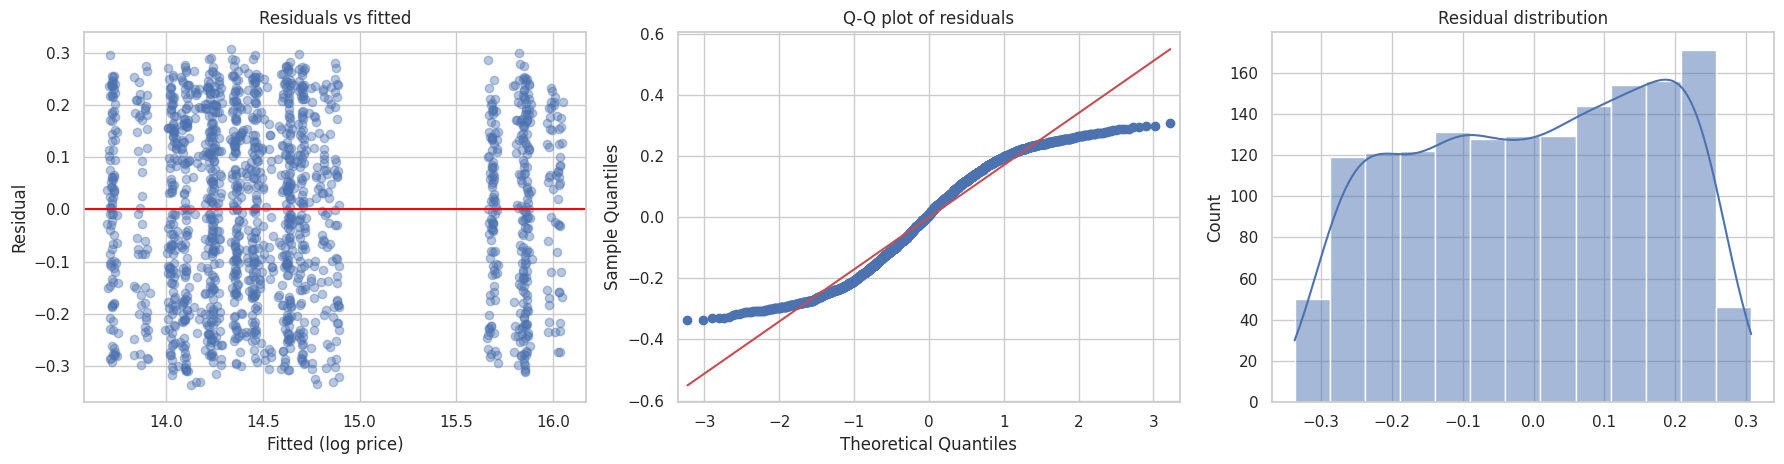

Durbin-Watson: 2.01
Breusch-Pagan p-value: 0.3347
Shapiro-Wilk p-value : 0.0


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/diagnostic.py:1217: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  resols = OLS(y, x).fit()
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.


Highest VIFs (values > 10 signal multicollinearity -> motivates Ridge/Lasso):


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stat

,feature,VIF
9,Brand_MG,"1,000,799,917,193,443.50"
6,Brand_Honda,"1,000,799,917,193,443.50"
10,Brand_Mahindra,"1,000,799,917,193,443.50"
7,Brand_Hyundai,"1,000,799,917,193,443.50"
8,Brand_Kia,"1,000,799,917,193,443.50"
16,Vehicle_Type_Luxury Sedan,"1,000,799,917,193,443.50"
15,Vehicle_Type_Luxury SUV,"1,000,799,917,193,443.50"
14,Brand_Toyota,"1,000,799,917,193,443.50"
13,Brand_Tata,"1,000,799,917,193,443.50"
11,Brand_Maruti Suzuki,"1,000,799,917,193,443.50"


In [17]:
# Diagnostics: residuals, normality, multicollinearity (VIF)
resid, fitted = ols.resid, ols.fittedvalues
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
axes[0].scatter(fitted, resid, alpha=.4); axes[0].axhline(0, color="red")
axes[0].set_xlabel("Fitted (log price)"); axes[0].set_ylabel("Residual"); axes[0].set_title("Residuals vs fitted")
sm.qqplot(resid, line="s", ax=axes[1]); axes[1].set_title("Q-Q plot of residuals")
sns.histplot(resid, kde=True, ax=axes[2]); axes[2].set_title("Residual distribution")
plt.tight_layout(); plt.show()

from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
print("Durbin-Watson:", round(durbin_watson(resid), 2))
print("Breusch-Pagan p-value:", round(het_breuschpagan(resid, sm.add_constant(Xtr))[1], 4))
print("Shapiro-Wilk p-value :", round(stats.shapiro(resid.sample(min(len(resid), 5000), random_state=1))[1], 4))

Xv = sm.add_constant(Xtr)
vif = pd.DataFrame({"feature": Xv.columns,
                    "VIF": [variance_inflation_factor(Xv.values, i) for i in range(Xv.shape[1])]})
print("\nHighest VIFs (values > 10 signal multicollinearity -> motivates Ridge/Lasso):")
display(vif[vif.feature != "const"].sort_values("VIF", ascending=False).head(10))

In [18]:
Xtr_f, Xte_f = X_full.loc[idx_train], X_full.loc[idx_test]

ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 60), cv=5)).fit(Xtr_f, ytr)
lasso = make_pipeline(StandardScaler(), LassoCV(cv=5, n_alphas=100, max_iter=20000, random_state=RANDOM_STATE)).fit(Xtr_f, ytr)

ridge_coef = pd.Series(ridge[-1].coef_, index=Xtr_f.columns)
lasso_coef = pd.Series(lasso[-1].coef_, index=Xtr_f.columns)
n_lasso = int((lasso_coef != 0).sum())

print(f"Ridge best alpha: {ridge[-1].alpha_:.4f}")
print(f"Lasso best alpha: {lasso[-1].alpha_:.6f} | features kept: {n_lasso} of {len(lasso_coef)}")

# an un-penalised model on the same full feature set, for a fair comparison
ols_full = LinearRegression().fit(Xtr_f, ytr)
evaluate("OLS (full features)", ols_full, Xtr_f, Xte_f)
evaluate("Ridge", ridge, Xtr_f, Xte_f)
evaluate("Lasso", lasso, Xtr_f, Xte_f, n_features=n_lasso)
display(pd.DataFrame(RESULTS[-3:]).set_index("Model"))

Ridge best alpha: 9.2491
Lasso best alpha: 0.003859 | features kept: 25 of 61


,R2_log,R2_INR,RMSE_INR_lakh,MAE_INR_lakh,MAPE_%,n_features
Model,,,,,,
OLS (full features),0.93,0.94,5.88,4.04,14.72,61
Ridge,0.93,0.94,5.91,4.06,14.73,61
Lasso,0.93,0.94,5.96,4.08,14.68,25


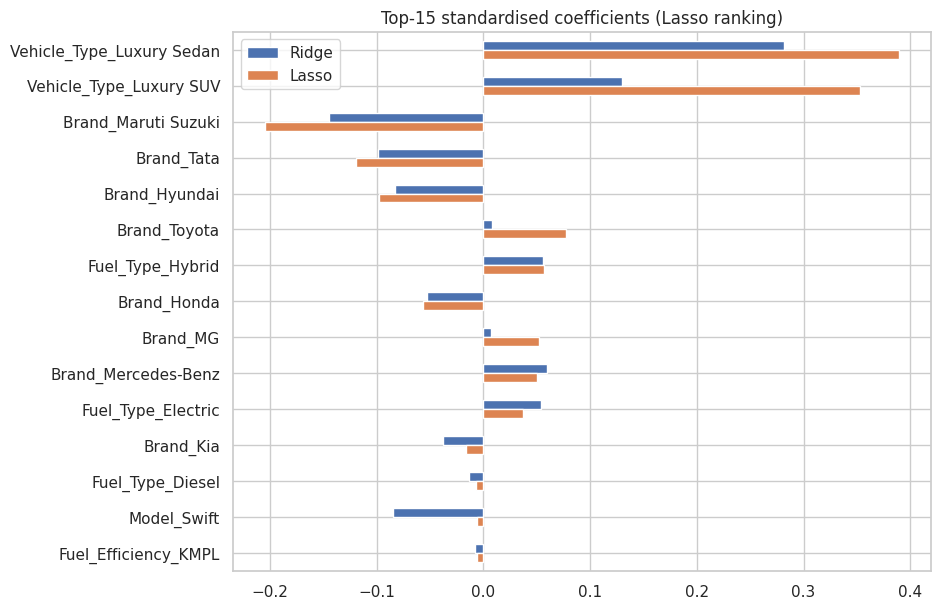

Variables removed by Lasso: ['Seating_Capacity', 'Engine_CC', 'EV_Range_KM', 'Manufacturing_Year', 'Brand_Mahindra', 'Vehicle_Type_MUV', 'Vehicle_Type_SUV', 'Transmission_Manual', 'Variant_Mid', 'Variant_Top', 'Model_Altroz', 'Model_Amaze', 'Model_Astor', 'Model_Brezza', 'Model_C-Class', 'Model_Carens', 'Model_City', 'Model_Creta', 'Model_Dzire', 'Model_Elevate', 'Model_Exter', 'Model_Fortuner', 'Model_Glanza', 'Model_Grand Vitara', 'Model_Harrier', 'Model_Innova Hycross', 'Model_Nexon', 'Model_Punch', 'Model_Scorpio N', 'Model_Seltos', 'Model_Tiago', 'Model_Verna', 'Model_X1', 'Model_XUV 3XO', 'Model_ZS EV', 'Model_i20']


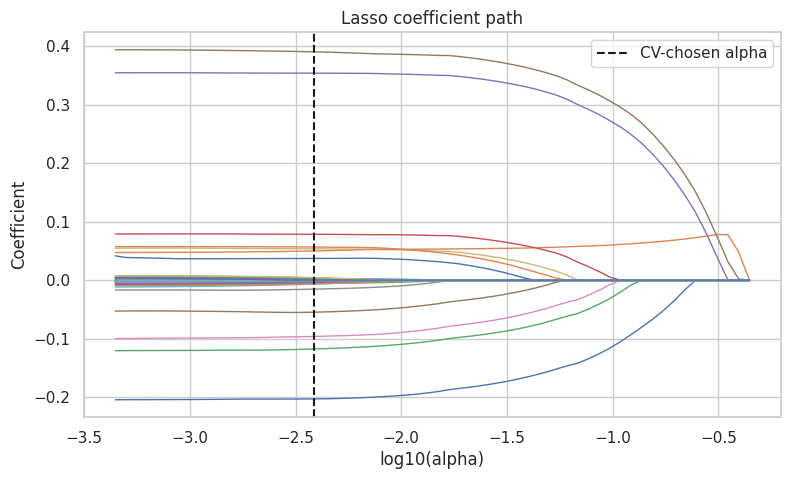

In [19]:
# Coefficient comparison and Lasso path
top = lasso_coef.abs().sort_values(ascending=False).head(15).index
comp = pd.DataFrame({"Ridge": ridge_coef[top], "Lasso": lasso_coef[top]})
comp.plot(kind="barh", figsize=(9, 7)); plt.gca().invert_yaxis()
plt.title("Top-15 standardised coefficients (Lasso ranking)"); plt.show()

print("Variables removed by Lasso:", list(lasso_coef[lasso_coef == 0].index))

alphas, coefs, _ = lasso_path(StandardScaler().fit_transform(Xtr_f), ytr, n_alphas=60)
plt.figure(figsize=(9, 5))
for c in coefs: plt.plot(np.log10(alphas), c, lw=1)
plt.axvline(np.log10(lasso[-1].alpha_), color="k", ls="--", label="CV-chosen alpha")
plt.xlabel("log10(alpha)"); plt.ylabel("Coefficient"); plt.title("Lasso coefficient path"); plt.legend(); plt.show()

In [20]:
grid = GridSearchCV(DecisionTreeRegressor(random_state=RANDOM_STATE),
                    param_grid={"max_depth": [3, 4, 5, 6, 8, 10, 12], "min_samples_leaf": [3, 5, 10, 20, 40]},
                    cv=5, scoring="r2", n_jobs=-1).fit(Xtr_f, ytr)
tree = grid.best_estimator_
print("Best params:", grid.best_params_, "| CV R2:", round(grid.best_score_, 4))
print(evaluate("Decision Tree", tree, Xtr_f, Xte_f))

Best params: {'max_depth': 12, 'min_samples_leaf': 40} | CV R2: 0.9276
{'Model': 'Decision Tree', 'R2_log': 0.9270822016108363, 'R2_INR': 0.9238856017682965, 'RMSE_INR_lakh': np.float64(6.658880978305236), 'MAE_INR_lakh': 4.307416814843379, 'MAPE_%': np.float64(14.979522340176372), 'n_features': 61}


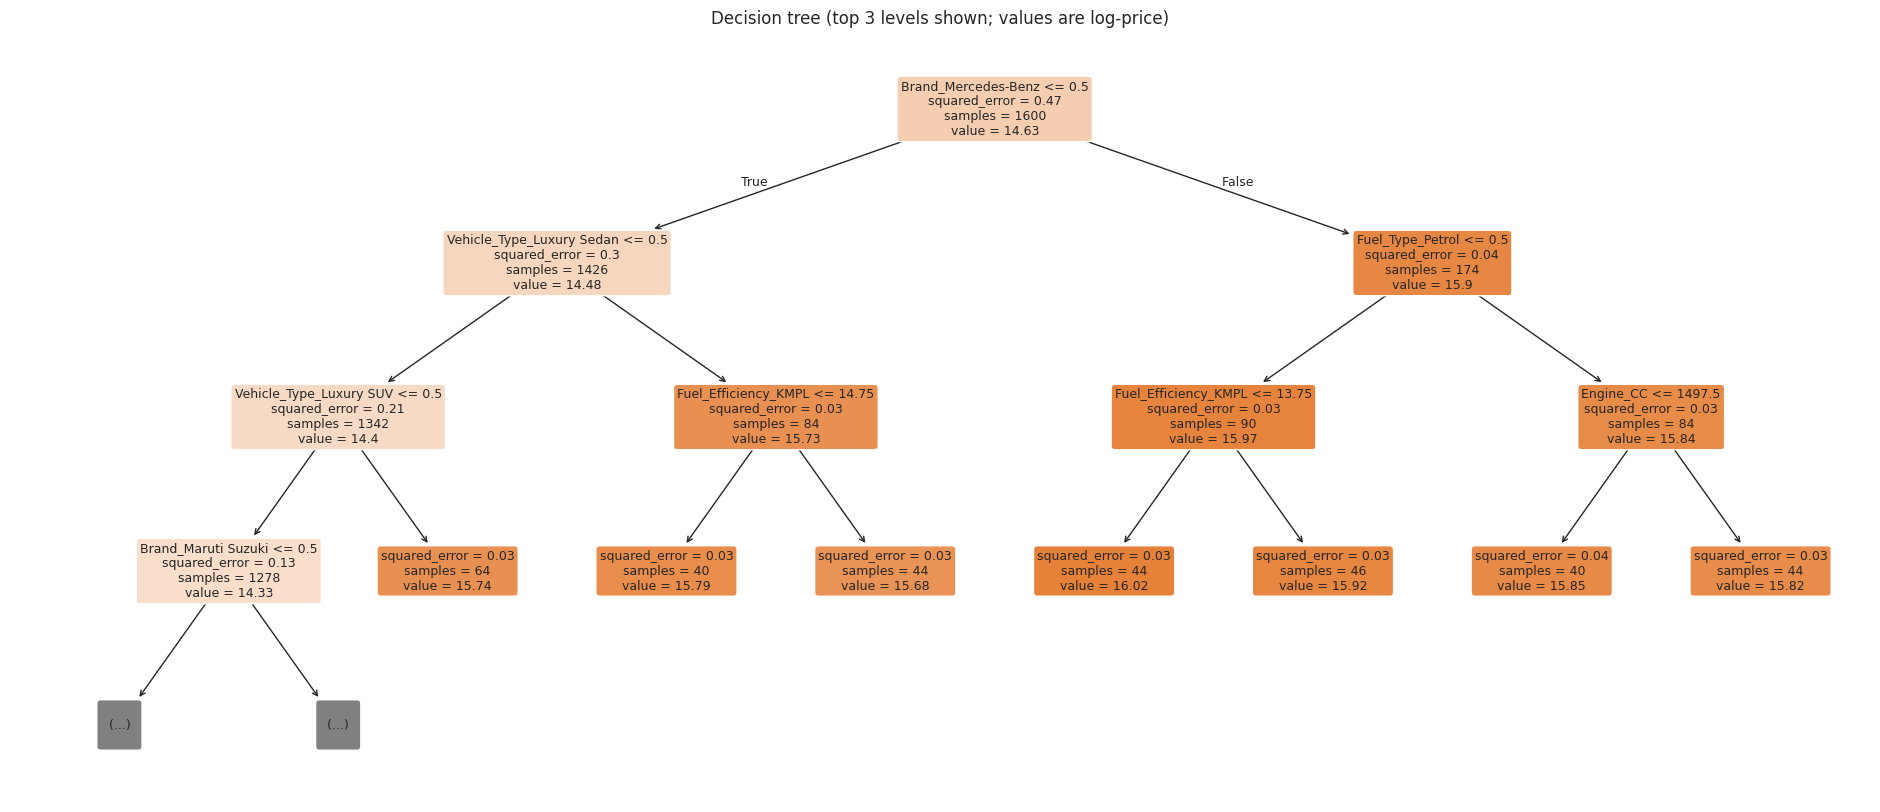

|--- Brand_Mercedes-Benz <= 0.50
|   |--- Vehicle_Type_Luxury Sedan <= 0.50
|   |   |--- Vehicle_Type_Luxury SUV <= 0.50
|   |   |   |--- Brand_Maruti Suzuki <= 0.50
|   |   |   |   |--- truncated branch of depth 9
|   |   |   |--- Brand_Maruti Suzuki >  0.50
|   |   |   |   |--- truncated branch of depth 3
|   |   |--- Vehicle_Type_Luxury SUV >  0.50
|   |   |   |--- value: [15.74]
|   |--- Vehicle_Type_Luxury Sedan >  0.50
|   |   |--- Fuel_Efficiency_KMPL <= 14.75
|   |   |   |--- value: [15.79]
|   |   |--- Fuel_Efficiency_KMPL >  14.75
|   |   |   |--- value: [15.68]
|--- Brand_Mercedes-Benz >  0.50
|   |--- Fuel_Type_Petrol <= 0.50
|   |   |--- Fuel_Efficiency_KMPL <= 13.75
|   |   |   |--- value: [16.02]
|   |   |--- Fuel_Efficiency_KMPL >  13.75
|   |   |   |--- value: [15.92]
|   |--- Fuel_Type_Petrol >  0.50
|   |   |--- Engine_CC <= 1497.50
|   |   |   |--- value: [15.85]
|   |   |--- Engine_CC >  1497.50
|   |   |   |--- value: [15.82]



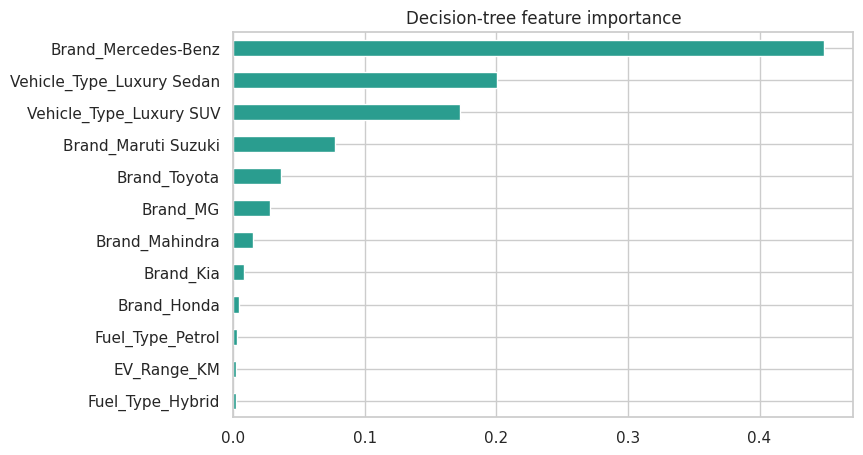

In [21]:
plt.figure(figsize=(24, 10))
plot_tree(tree, max_depth=3, feature_names=Xtr_f.columns, filled=True, rounded=True, fontsize=9, precision=2)
plt.title("Decision tree (top 3 levels shown; values are log-price)"); plt.show()

print(export_text(tree, feature_names=list(Xtr_f.columns), max_depth=3))

imp = pd.Series(tree.feature_importances_, index=Xtr_f.columns).sort_values(ascending=False).head(12)
imp.sort_values().plot(kind="barh", figsize=(8, 5), color="#2a9d8f"); plt.title("Decision-tree feature importance"); plt.show()

In [22]:
param_dist = {"n_estimators": [200, 300, 500], "max_depth": [None, 8, 12, 16],
              "min_samples_leaf": [1, 2, 4, 8], "max_features": ["sqrt", 0.3, 0.5, 1.0]}
rs = RandomizedSearchCV(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
                        param_distributions=param_dist, n_iter=15, cv=5, scoring="r2",
                        random_state=RANDOM_STATE, n_jobs=1).fit(Xtr_f, ytr)
rf = rs.best_estimator_
print("Best params:", rs.best_params_, "| CV R2:", round(rs.best_score_, 4))
print(evaluate("Random Forest", rf, Xtr_f, Xte_f))

Best params: {'n_estimators': 200, 'min_samples_leaf': 8, 'max_features': 0.5, 'max_depth': 16} | CV R2: 0.9311
{'Model': 'Random Forest', 'R2_log': 0.9302644151161878, 'R2_INR': 0.9329698215197131, 'RMSE_INR_lakh': np.float64(6.2488921777009825), 'MAE_INR_lakh': 4.170502072448876, 'MAPE_%': np.float64(14.7915477897921), 'n_features': 61}


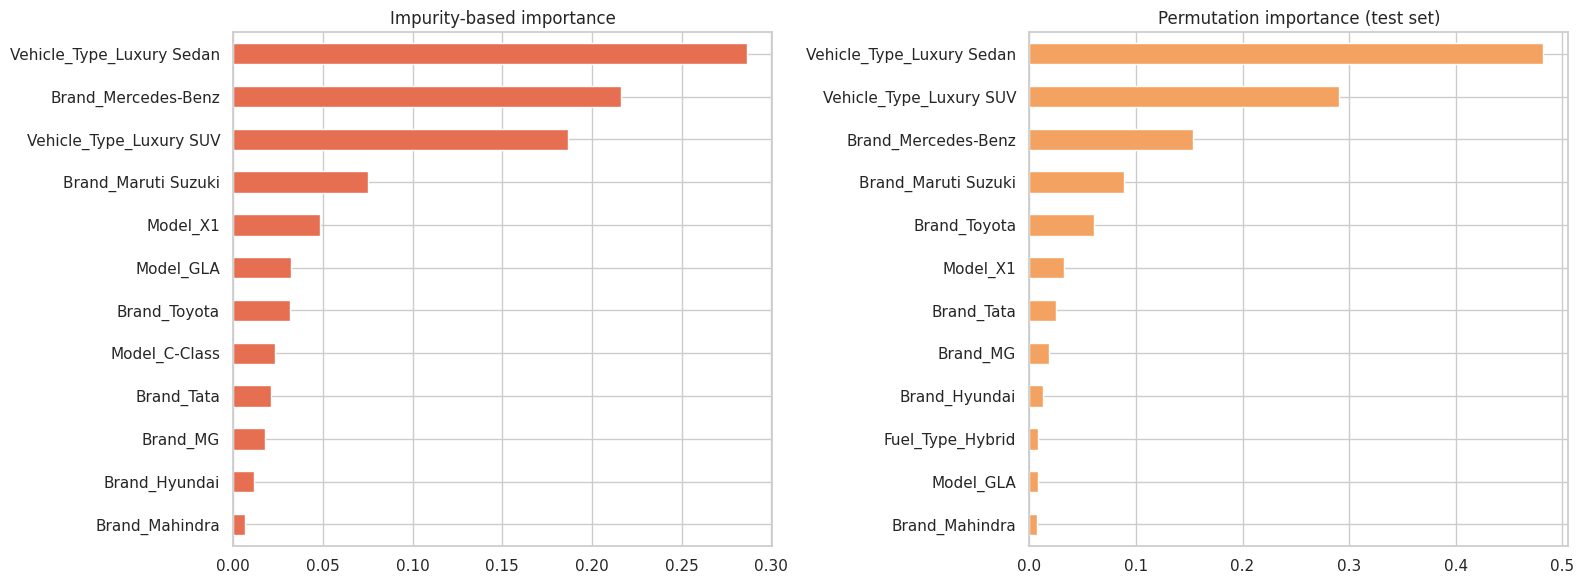

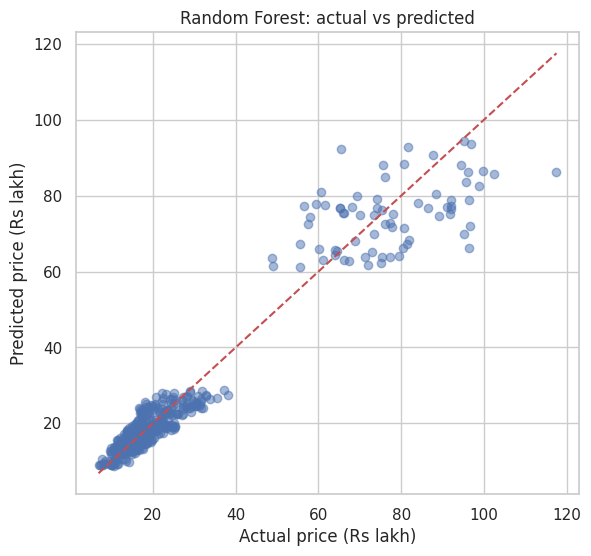

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
imp_rf = pd.Series(rf.feature_importances_, index=Xtr_f.columns).sort_values(ascending=False).head(12)
imp_rf.sort_values().plot(kind="barh", ax=axes[0], color="#e76f51"); axes[0].set_title("Impurity-based importance")

perm = permutation_importance(rf, Xte_f, yte, n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
perm_s = pd.Series(perm.importances_mean, index=Xte_f.columns).sort_values(ascending=False).head(12)
perm_s.sort_values().plot(kind="barh", ax=axes[1], color="#f4a261"); axes[1].set_title("Permutation importance (test set)")
plt.tight_layout(); plt.show()

# Predicted vs actual
pred = np.exp(rf.predict(Xte_f)); act = np.exp(yte)
plt.figure(figsize=(6.5, 6)); plt.scatter(act / 1e5, pred / 1e5, alpha=.5)
lim = [act.min() / 1e5, act.max() / 1e5]; plt.plot(lim, lim, "r--")
plt.xlabel("Actual price (Rs lakh)"); plt.ylabel("Predicted price (Rs lakh)"); plt.title("Random Forest: actual vs predicted"); plt.show()

feature_set,A: buyer & deal,B: vehicle & price
k,,
2,0.18,0.47
3,0.14,0.56
4,0.13,0.57
5,0.13,0.60
6,0.13,0.62
7,0.13,0.63
8,0.14,0.56


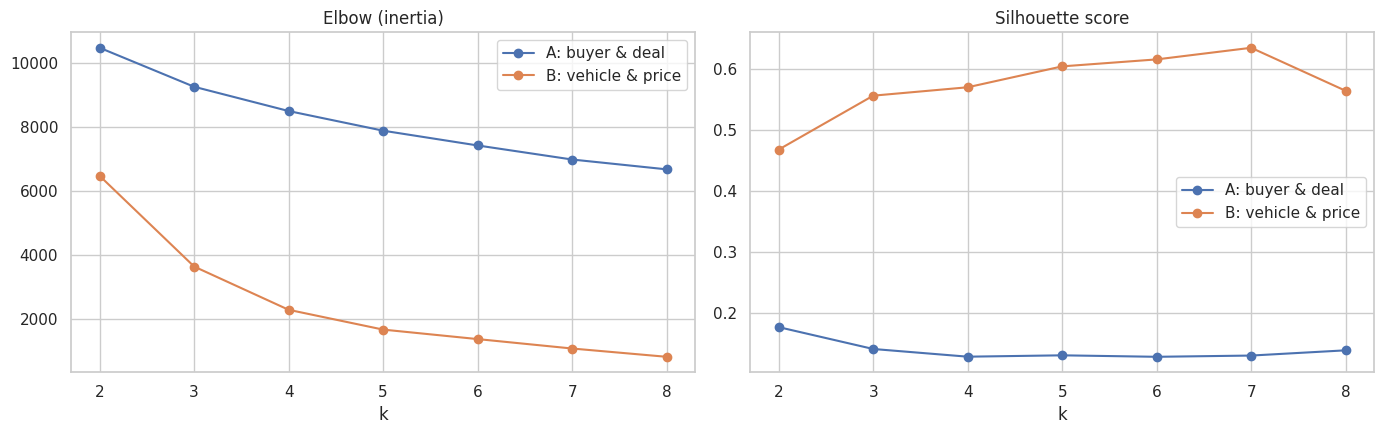

In [24]:
def prep_cluster(cols, log_cols):
    d = df[cols].copy()
    for c in log_cols: d[c] = np.log1p(d[c])
    return pd.DataFrame(StandardScaler().fit_transform(d), columns=cols, index=df.index)

sets = {
    "A: buyer & deal": (["Age", "Annual_Income_INR", "Ex_Showroom_Price_INR", "Discount_Pct", "Customer_Rating", "Delivery_Time_Days"],
                        ["Annual_Income_INR", "Ex_Showroom_Price_INR"]),
    "B: vehicle & price": (["Ex_Showroom_Price_INR", "Engine_CC", "Seating_Capacity", "Is_EV", "Is_Luxury"],
                           ["Ex_Showroom_Price_INR"]),
}
rows, Z = [], {}
for name, (cols, logc) in sets.items():
    Z[name] = prep_cluster(cols, logc)
    for k in range(2, 9):
        km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Z[name])
        rows.append({"feature_set": name, "k": k, "inertia": km.inertia_,
                     "silhouette": silhouette_score(Z[name], km.labels_),
                     "calinski_harabasz": calinski_harabasz_score(Z[name], km.labels_)})
sel = pd.DataFrame(rows)
display(sel.pivot(index="k", columns="feature_set", values="silhouette"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for name in sets:
    s = sel[sel.feature_set == name]
    axes[0].plot(s.k, s.inertia, marker="o", label=name); axes[1].plot(s.k, s.silhouette, marker="o", label=name)
axes[0].set_title("Elbow (inertia)"); axes[1].set_title("Silhouette score")
for a in axes: a.set_xlabel("k"); a.legend()
plt.tight_layout(); plt.show()

Chosen: B: vehicle & price with k = 7 (silhouette = 0.635)


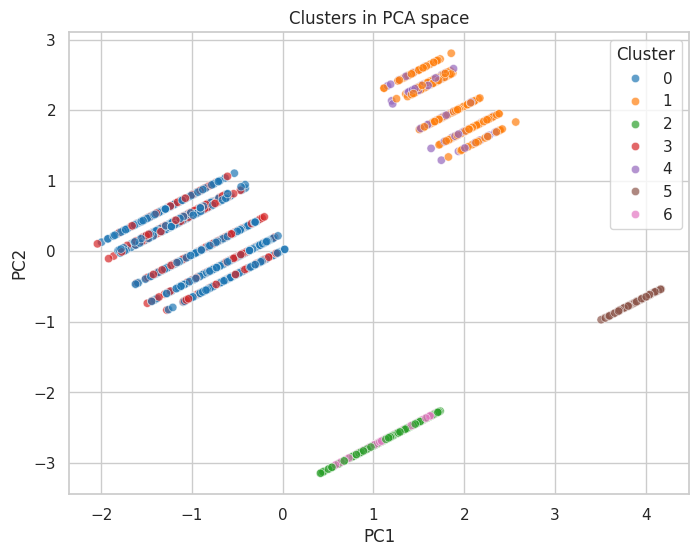

,size,avg_age,avg_income_lakh,avg_price_lakh,avg_discount_pct,avg_engine_cc,ev_share_pct,luxury_share_pct,finance_pct,cancel_pct,avg_rating,size_pct
Cluster,,,,,,,,,,,,
0,927,42.78,14.64,17.26,5.50,"1,554.17",0.00,0.00,70.98,7.23,3.97,46.35
1,246,43.35,14.14,75.48,5.32,"1,565.74",0.00,100.00,69.51,8.13,4.00,12.30
2,197,42.34,14.43,18.67,5.51,0.00,100.00,0.00,71.57,8.63,3.98,9.85
3,394,43.03,14.15,18.84,5.77,"1,604.41",0.00,0.00,69.54,8.12,4.00,19.70
4,81,44.41,13.40,73.95,5.40,"1,566.59",0.00,100.00,67.90,7.41,3.95,4.05
5,68,40.90,14.26,83.25,5.12,0.00,100.00,100.00,67.65,1.47,4.14,3.40
6,87,42.36,14.97,20.11,5.77,0.00,100.00,0.00,67.82,6.90,3.99,4.35


Vehicle_Type,Hatchback,Luxury SUV,Luxury Sedan,MUV,SUV,Sedan
Cluster,,,,,,
0,16.00,0.00,0.00,0.00,69.60,14.50
1,0.00,43.90,56.10,0.00,0.00,0.00
2,17.30,0.00,0.00,0.00,64.50,18.30
3,12.40,0.00,0.00,22.80,56.10,8.60
4,0.00,46.90,53.10,0.00,0.00,0.00
5,0.00,51.50,48.50,0.00,0.00,0.00
6,10.30,0.00,0.00,23.00,55.20,11.50


Brand,BMW,Honda,Hyundai,Kia,MG,Mahindra,Maruti Suzuki,Mercedes-Benz,Tata,Toyota
Cluster,,,,,,,,,,
0,0.00,14.50,13.80,9.20,12.60,13.60,12.00,0.00,14.30,10.00
1,47.20,0.00,0.00,0.00,0.00,0.00,0.00,52.80,0.00,0.00
2,0.00,14.70,13.70,7.10,9.60,15.20,14.70,0.00,11.20,13.70
3,0.00,10.40,7.90,18.30,9.60,12.40,8.40,0.00,10.90,22.10
4,42.00,0.00,0.00,0.00,0.00,0.00,0.00,58.00,0.00,0.00
5,48.50,0.00,0.00,0.00,0.00,0.00,0.00,51.50,0.00,0.00
6,0.00,9.20,16.10,20.70,14.90,10.30,10.30,0.00,5.70,12.60


In [25]:
# Picks the feature set / k with the best silhouette. Override manually if you prefer, e.g.
#   CHOSEN_SET, K_FINAL = "B: vehicle & price", 4
best = sel.sort_values("silhouette", ascending=False).iloc[0]
CHOSEN_SET, K_FINAL = best["feature_set"], int(best["k"])
print(f"Chosen: {CHOSEN_SET} with k = {K_FINAL} (silhouette = {best['silhouette']:.3f})")

km = KMeans(n_clusters=K_FINAL, n_init=20, random_state=RANDOM_STATE).fit(Z[CHOSEN_SET])
df["Cluster"] = km.labels_

# 2-D view using PCA
pcs = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(Z[CHOSEN_SET])
plt.figure(figsize=(8, 6))
sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=df["Cluster"], palette="tab10", alpha=.7)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("Clusters in PCA space"); plt.show()

# Cluster profile
profile = df.groupby("Cluster").agg(
    size=("Car_ID", "count"),
    avg_age=("Age", "mean"),
    avg_income_lakh=("Annual_Income_INR", lambda s: s.mean() / 1e5),
    avg_price_lakh=("Ex_Showroom_Price_INR", lambda s: s.mean() / 1e5),
    avg_discount_pct=("Discount_Pct", "mean"),
    avg_engine_cc=("Engine_CC", "mean"),
    ev_share_pct=("Is_EV", lambda s: s.mean() * 100),
    luxury_share_pct=("Is_Luxury", lambda s: s.mean() * 100),
    finance_pct=("Financed", lambda s: s.mean() * 100),
    cancel_pct=("Cancelled", lambda s: s.mean() * 100),
    avg_rating=("Customer_Rating", "mean"),
)
profile["size_pct"] = profile["size"] / len(df) * 100
display(profile)
display(pd.crosstab(df["Cluster"], df["Vehicle_Type"], normalize="index").mul(100).round(1))
display(pd.crosstab(df["Cluster"], df["Brand"], normalize="index").mul(100).round(1))

===== Target: Cancelled  (positive rate = 7.4%) =====
Test ROC-AUC: 0.548 | 5-fold CV AUC: 0.459 +/- 0.052
              precision    recall  f1-score   support

           0      0.929     0.632     0.752       370
           1      0.081     0.400     0.135        30

    accuracy                          0.615       400
   macro avg      0.505     0.516     0.444       400
weighted avg      0.865     0.615     0.706       400



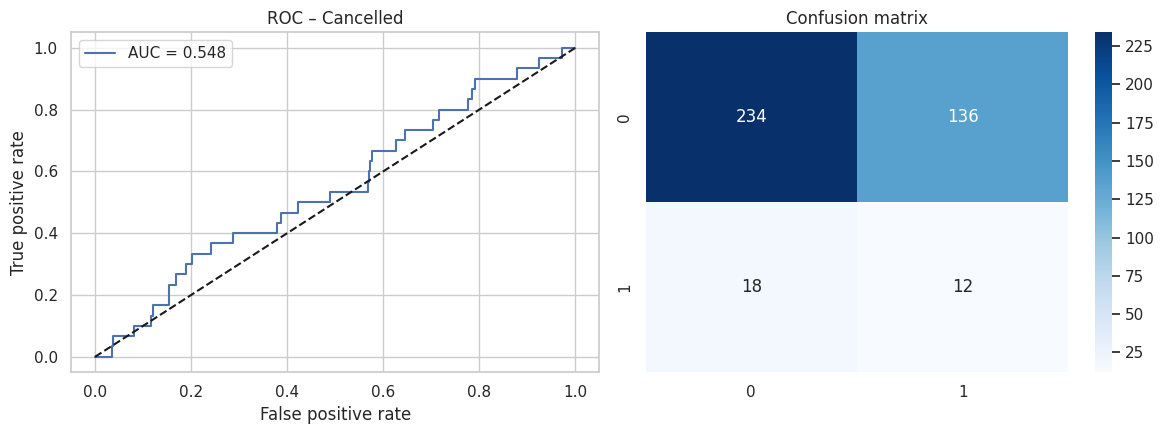

Largest effects (odds ratio per 1 SD / vs reference level):


,odds_ratio_per_1SD
Ex_Showroom_Price_INR,1.45
Sales_Channel_Online Booking,1.38
Sales_Channel_Dealer Referral,1.32
Brand_Honda,1.26
Vehicle_Type_Luxury SUV,0.78
Brand_Tata,1.22
Fuel_Type_Hybrid,1.22
Sales_Channel_Showroom,1.20


--> Verdict: no meaningful predictive signal (AUC < 0.60)

===== Target: Financed  (positive rate = 70.2%) =====
Test ROC-AUC: 0.488 | 5-fold CV AUC: 0.439 +/- 0.012
              precision    recall  f1-score   support

           0      0.282     0.487     0.357       119
           1      0.686     0.473     0.560       281

    accuracy                          0.477       400
   macro avg      0.484     0.480     0.458       400
weighted avg      0.565     0.477     0.500       400



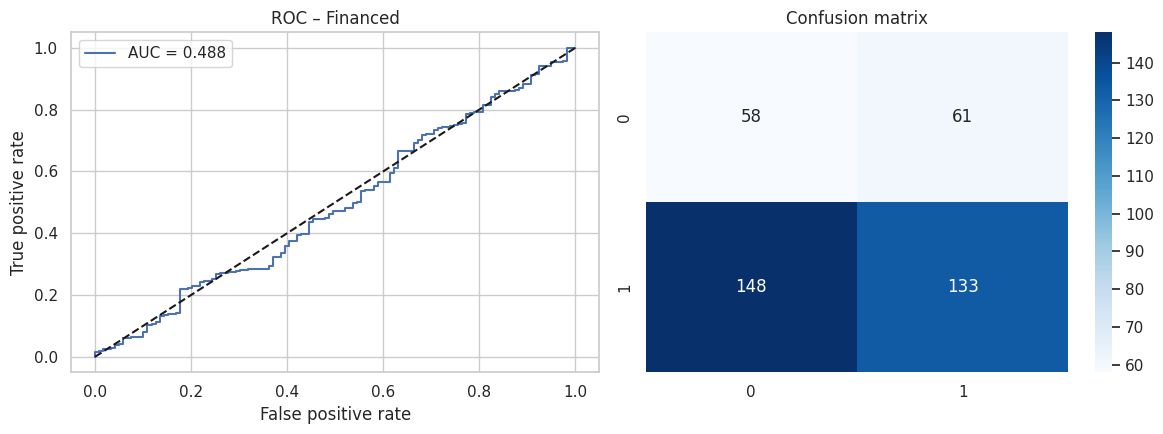

Largest effects (odds ratio per 1 SD / vs reference level):


,odds_ratio_per_1SD
Fuel_Type_Petrol,0.79
Ex_Showroom_Price_INR,0.84
Fuel_Type_Electric,0.86
Fuel_Type_Hybrid,0.88
Vehicle_Type_Luxury SUV,1.10
Vehicle_Type_SUV,1.10
Fuel_Type_Diesel,0.91
Occupation_Teacher,0.92


--> Verdict: no meaningful predictive signal (AUC < 0.60)



In [26]:
cust_cats = ["Gender", "Customer_Type", "Occupation", "Brand", "Vehicle_Type", "Fuel_Type", "Transmission",
             "Sales_Channel", "Booking_Source", "Insurance_Purchased", "Extended_Warranty", "Old_Car_Exchange"]

def make_clf_X(extra_drop=()):
    X = df[["Age", "Annual_Income_INR", "Ex_Showroom_Price_INR", "Discount_Pct"] + cust_cats].copy()
    X["Annual_Income_INR"] = np.log(X["Annual_Income_INR"]); X["Ex_Showroom_Price_INR"] = np.log(X["Ex_Showroom_Price_INR"])
    X = X.drop(columns=list(extra_drop))
    return pd.get_dummies(X, drop_first=True, dtype=float)

def run_logit(target_col, X):
    y = df[target_col]
    Xtr, Xte, ytr_c, yte_c = train_test_split(X, y, test_size=.2, stratify=y, random_state=RANDOM_STATE)
    clf = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000))
    clf.fit(Xtr, ytr_c)
    proba = clf.predict_proba(Xte)[:, 1]; pred = clf.predict(Xte)
    cv_auc = cross_val_score(clf, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), scoring="roc_auc")
    auc = roc_auc_score(yte_c, proba)
    print(f"===== Target: {target_col}  (positive rate = {y.mean():.1%}) =====")
    print(f"Test ROC-AUC: {auc:.3f} | 5-fold CV AUC: {cv_auc.mean():.3f} +/- {cv_auc.std():.3f}")
    print(classification_report(yte_c, pred, digits=3))
    fpr, tpr, _ = roc_curve(yte_c, proba)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].plot(fpr, tpr, label=f"AUC = {auc:.3f}"); axes[0].plot([0, 1], [0, 1], "k--"); axes[0].legend()
    axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate"); axes[0].set_title(f"ROC – {target_col}")
    sns.heatmap(confusion_matrix(yte_c, pred), annot=True, fmt="d", cmap="Blues", ax=axes[1]); axes[1].set_title("Confusion matrix")
    plt.tight_layout(); plt.show()
    odds = pd.Series(np.exp(clf[-1].coef_[0]), index=X.columns, name="odds_ratio_per_1SD")
    print("Largest effects (odds ratio per 1 SD / vs reference level):")
    display(odds.iloc[(odds - 1).abs().argsort()[::-1][:8]].to_frame())
    verdict = "no meaningful predictive signal (AUC < 0.60)" if auc < 0.60 else "some predictive signal"
    print(f"--> Verdict: {verdict}\n")
    return auc

auc_cancel  = run_logit("Cancelled", make_clf_X())
auc_finance = run_logit("Financed", make_clf_X())

Overall KMO = 0.300  ->  NOT adequate for factor analysis (< 0.6)
Bartlett chi2 = 68,287.1, df = 66, p = 0


,Age,Annual_Income_INR,Seating_Capacity,Engine_CC,Fuel_Efficiency_KMPL,Ex_Showroom_Price_INR,Discount_INR,Loan_Amount_INR,Down_Payment_INR,Loan_Tenure_Years,Customer_Rating,Delivery_Time_Days
KMO,0.64,0.58,0.50,0.74,0.60,0.34,0.28,0.24,0.25,1.00,0.53,0.63


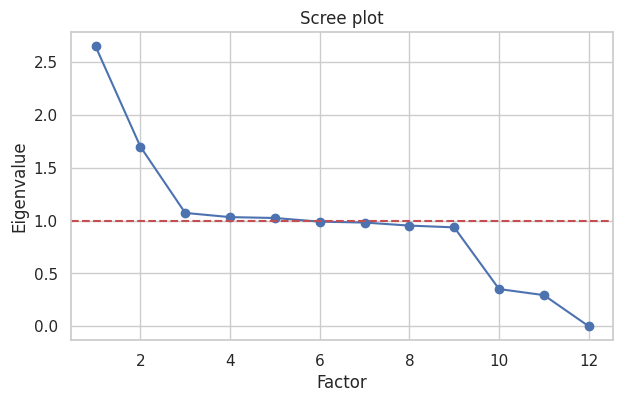

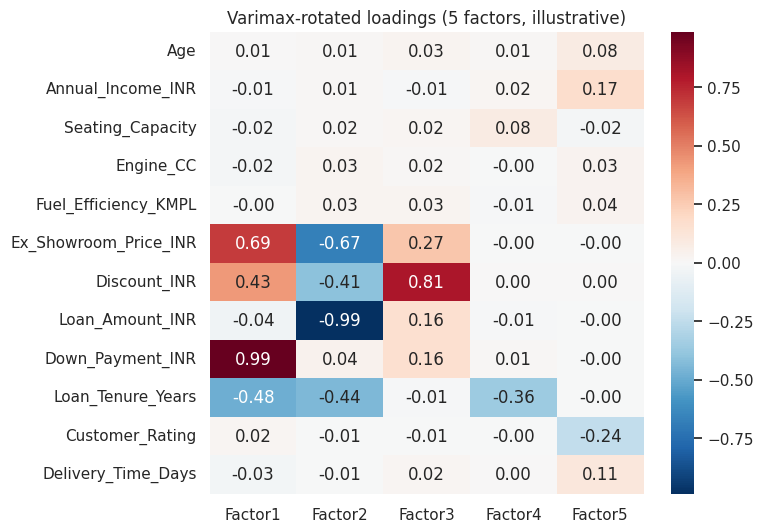

Interpretation: with KMO below 0.6, factor analysis is not statistically justified for this dataset;
the only real structure is the price/discount/loan block and the engine-vs-mileage pair.


In [27]:
fa_cols = ["Age", "Annual_Income_INR", "Seating_Capacity", "Engine_CC", "Fuel_Efficiency_KMPL",
           "Ex_Showroom_Price_INR", "Discount_INR", "Loan_Amount_INR", "Down_Payment_INR",
           "Loan_Tenure_Years", "Customer_Rating", "Delivery_Time_Days"]
D = df[fa_cols].copy(); D["Fuel_Efficiency_KMPL"] = D["Fuel_Efficiency_KMPL"].fillna(D["Fuel_Efficiency_KMPL"].median())
R = D.corr().values; n, p = D.shape

def kmo(R):
    inv = np.linalg.pinv(R)
    partial = -inv / np.sqrt(np.outer(np.diag(inv), np.diag(inv)))
    np.fill_diagonal(partial, 0); R0 = R.copy(); np.fill_diagonal(R0, 0)
    per_var = (R0 ** 2).sum(0) / ((R0 ** 2).sum(0) + (partial ** 2).sum(0))
    overall = (R0 ** 2).sum() / ((R0 ** 2).sum() + (partial ** 2).sum())
    return overall, per_var

kmo_all, kmo_var = kmo(R)
sign, logdet = np.linalg.slogdet(R)
chi2 = -(n - 1 - (2 * p + 5) / 6) * logdet; dof = p * (p - 1) / 2
print(f"Overall KMO = {kmo_all:.3f}  ->  {'adequate' if kmo_all >= 0.6 else 'NOT adequate for factor analysis (< 0.6)'}")
print(f"Bartlett chi2 = {chi2:,.1f}, df = {dof:.0f}, p = {stats.chi2.sf(chi2, dof):.4g}")
display(pd.Series(kmo_var, index=fa_cols, name="KMO").to_frame().T)

eig = np.sort(np.linalg.eigvalsh(R))[::-1]
plt.figure(figsize=(7, 4)); plt.plot(range(1, p + 1), eig, marker="o"); plt.axhline(1, color="r", ls="--")
plt.xlabel("Factor"); plt.ylabel("Eigenvalue"); plt.title("Scree plot"); plt.show()

k = max(2, int((eig > 1).sum()))
fa = FactorAnalysis(n_components=k, rotation="varimax", random_state=RANDOM_STATE).fit(StandardScaler().fit_transform(D))
loadings = pd.DataFrame(fa.components_.T, index=fa_cols, columns=[f"Factor{i+1}" for i in range(k)])
plt.figure(figsize=(7, 6)); sns.heatmap(loadings, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title(f"Varimax-rotated loadings ({k} factors, illustrative)"); plt.show()
print("Interpretation: with KMO below 0.6, factor analysis is not statistically justified for this dataset;")
print("the only real structure is the price/discount/loan block and the engine-vs-mileage pair.")

,R2_log,R2_INR,RMSE_INR_lakh,MAE_INR_lakh,MAPE_%,n_features
Model,,,,,,
OLS (full features),0.93,0.94,5.88,4.04,14.72,61
Linear Regression,0.93,0.94,5.90,4.04,14.61,26
Ridge,0.93,0.94,5.91,4.06,14.73,61
Lasso,0.93,0.94,5.96,4.08,14.68,25
Random Forest,0.93,0.93,6.25,4.17,14.79,61
Decision Tree,0.93,0.92,6.66,4.31,14.98,61


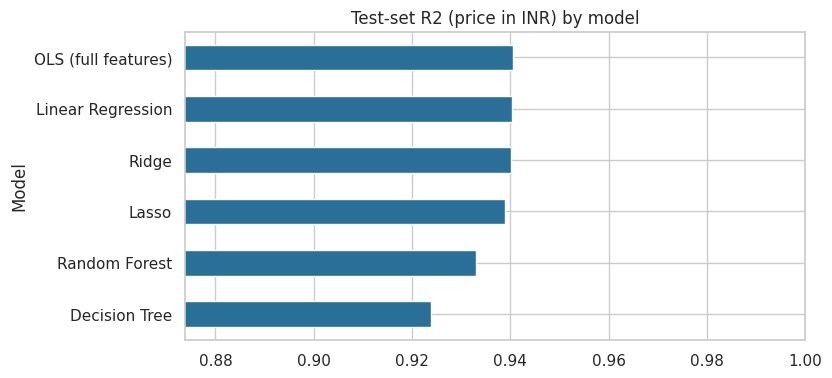

Segmentation (K-Means): B: vehicle & price | k = 7
Logistic AUC  -> Cancelled: 0.548 | Financed: 0.488


In [28]:
res = pd.DataFrame(RESULTS).drop_duplicates("Model", keep="last").set_index("Model").sort_values("R2_INR", ascending=False)
display(res)

ax = res["R2_INR"].sort_values().plot(kind="barh", figsize=(8, 4), color="#2a6f97")
ax.set_xlim(res["R2_INR"].min() - 0.05, 1.0); ax.set_title("Test-set R2 (price in INR) by model"); plt.show()

print("Segmentation (K-Means):", CHOSEN_SET, "| k =", K_FINAL)
print(f"Logistic AUC  -> Cancelled: {auc_cancel:.3f} | Financed: {auc_finance:.3f}")